# Spaceship Titanic: Notebook Final (CRISP-DM)

Notebook ini memuat seluruh alur, dari data mentah sampai berkas submisi, dalam enam fase CRISP-DM.

| Fase CRISP-DM | Isi |
|---|---|
| 1. Business Understanding | Latar belakang, tujuan teknis, metrik, dan kriteria keberhasilan |
| 2. Data Understanding | Deskripsi data, nilai kosong, distribusi, aturan logika data, independensi baris (grup) |
| 3. Data Preparation | Imputasi struktural, feature engineering, eksplorasi terhadap target, dataset bersih |
| 4. Modeling | Pipeline, baseline, perbandingan model, ablation, hyperparameter tuning (nested CV) |
| 5. Evaluation | Audit kebocoran, interpretasi, peninjauan terhadap kriteria keberhasilan, kesimpulan |
| 6. Deployment | Model akhir, prediksi data uji, berkas submisi, rencana pemakaian |

Validasi memakai StratifiedGroupKFold (berdasarkan `Group`). Imputasi statistik, encoding, dan scaling berada di dalam Pipeline per fold, jadi tidak bocor ke data validasi.

## Data

Data berasal dari kompetisi [Spaceship Titanic](https://www.kaggle.com/competitions/spaceship-titanic/data) di Kaggle. Data tidak disertakan bersama notebook ini karena aturan kompetisi melarang menyebarkannya ke pihak yang bukan peserta. Untuk menjalankan ulang, unduh data dari halaman kompetisi (butuh akun Kaggle dan persetujuan aturan), lalu taruh berkas berikut di folder `data/raw/` di samping notebook:

- `train.csv`
- `test.csv`
- `sample_submission.csv`

Notebook membuat `data/clean/` dan `data/submission.csv` sendiri saat dijalankan.

## Ringkasan eksekutif

Masalahnya adalah memprediksi penumpang Spaceship Titanic yang berpindah dimensi (`Transported`) dari data manifes kapal.

- Dua sinyal terkuat adalah `CryoSleep` dan ada tidaknya belanja (`NoSpend`). Penumpang yang tidur beku jauh lebih sering ikut berpindah, dan keduanya saling terkait karena penumpang yang tidur beku tidak berbelanja.
- Sebagian nilai kosong bisa diisi dengan aturan pasti dari data itu sendiri (misalnya `CryoSleep` berarti belanja nol), tanpa memakai target. Sisanya tampak tersebar acak.
- Penumpang satu grup cenderung bernasib sama, jadi validasi dilakukan per grup agar tidak terlalu optimis. Tidak ada tanda pergeseran sebaran antara data latih dan data uji.
- Model boosting jauh di atas baseline linear, dan CatBoost memberi hasil terbaik. Tuning hyperparameter, fitur tambahan, dan ensemble tidak memberi perbaikan yang terbukti.
- Pelatihan dengan label acak tidak menghasilkan skor di atas kebetulan, dan probabilitas model terkalibrasi baik. Accuracy paling rendah ada pada penumpang dari Earth (Deck G) dan anak-anak.
- Fitur yang paling berpengaruh adalah belanja di `Spa`, `VRDeck`, `FoodCourt`, dan `RoomService`, serta lokasi kabin (`Deck`).
- Skor leaderboard publik sedikit di bawah skor validasi. Selisihnya masih dalam rentang ketidakpastian pengambilan sampel data uji dan estimasi validasi.
- Belum dicoba: LightGBM dan imputasi berbasis model.

Angka hasil akhir (accuracy dan AUC nested CV beserta simpangan bakunya) ada di bagian Ringkasan pada fase Evaluation.

# Persiapan: Import Library

In [1]:
# Library untuk analisis data, visualisasi, dan modeling
import platform
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import catboost
import sklearn
import xgboost
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from scipy.stats import chi2_contingency, loguniform, randint, uniform

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, brier_score_loss, classification_report
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

%matplotlib inline
sns.set_theme(style="whitegrid")

SEED = 42  # satu seed global untuk seluruh notebook

T_MULAI = time.time()  # untuk mencatat waktu eksekusi total

print("Python  :", platform.python_version())
for paket in (pd, np, sklearn, xgboost, catboost):
    print(f"{paket.__name__:<9}:", paket.__version__)

Python  : 3.10.20
pandas   : 2.3.3
numpy    : 2.2.6
sklearn  : 1.7.2
xgboost  : 3.2.0
catboost : 1.2.10


# 1. Business Understanding

Kami mendapatkan pesan transmisi dari lokasi di 4 tahun cahaya jauhnya. Dan kami mendapat sebuah kabar tidak baik.

Spaceship Titanic yaitu sebuah kapal antariksa yang telah lepas landas beberapa bulan yang lalu. Kapal tersebut membawa 13.000 emigran dari tata surya kita menuju tiga eksoplanet layak huni yang baru ditemukan dan mengorbit bintang-bintang terdekat.

Namun, saat mengitari rute Alpha Centauri untuk mencapai destinasi pertamanya. Kapal tersebut bertabrakan dengan benda asing yang bersembunyi di debu luar angkasa.

Kapal masih bertahan dalam keadaan utuh, namun hampir setengah dari penumpang menghilang ke dimensi lain.

Jadi, untuk membantu kru dan menolong penumpang. Kita harus membuat model yang bisa memprediksi penumpang mana saja yang menghilang menggunakan rekaman yang dipulihkan dari komputer kapal antariksa tersebut

## Tujuan teknis dan kriteria keberhasilan

Tujuan teknisnya adalah klasifikasi biner untuk memprediksi `Transported` pada data uji. Metrik utamanya accuracy, yang juga dipakai penilaian kompetisi. Target hampir seimbang, jadi accuracy layak dipakai. ROC-AUC dan F1 dilaporkan sebagai pembanding.

Kriteria keberhasilan, dinilai di fase Evaluation:
1. Model terpilih lebih baik daripada baseline (Dummy dan Logistic Regression) pada nested CV, dan lebih baik dari Logistic Regression di sebagian besar fold.
2. Validasi tidak bocor: tidak ada grup yang terpecah antara data latih dan validasi, dan pelatihan dengan label acak menghasilkan skor mendekati tingkat kebetulan.
3. Performa dilaporkan sebagai rata-rata dan simpangan baku antar fold, bukan satu angka.

Tidak ada ambang accuracy mutlak yang ditetapkan sebelumnya, dan skor leaderboard tidak dipakai untuk memilih model. Skor itu hanya dibandingkan dengan hasil validasi di fase Evaluation, setelah model final ditentukan.

## Asumsi dan risiko

Asumsi:
- Data latih mewakili data uji. Hal ini diperiksa dengan adversarial validation di fase Modeling.
- Nilai kosong tersebar acak dan tidak berkaitan dengan target. Hal ini diperiksa di fase Data Understanding.
- Kesalahan dua arah (menandai penumpang yang tidak hilang, atau melewatkan yang hilang) dianggap sama mahalnya, karena kompetisi menilai accuracy.

Risiko:
- Anggota satu grup bisa terpecah antara data latih dan validasi, sehingga skor validasi terlalu optimis. Dicegah dengan validasi per grup.
- Memilih model dan hyperparameter pada data yang sama dengan penilaiannya membuat skor optimis. Dicegah dengan nested CV.
- Skor cross-validation bisa berbeda dari skor di data uji, karena data uji tidak berlabel. Selisihnya dibandingkan dengan skor leaderboard di fase Evaluation.

# 2. Data Understanding

## Deskripsi Data

### train.csv
Data pribadi sekitar dua pertiga (~8700) penumpang yang digunakan sebagai data latih.

- **PassengerId**: ID unik untuk setiap penumpang. Setiap ID berbentuk `gggg_pp`, dengan `gggg` menunjukkan kelompok tempat penumpang bepergian dan `pp` menunjukkan nomor urut penumpang dalam kelompok tersebut. Anggota suatu kelompok sering kali merupakan anggota keluarga, tetapi tidak selalu.
- **HomePlanet**: Planet tempat penumpang berangkat, umumnya merupakan planet tempat tinggal tetap penumpang.
- **CryoSleep**: Menunjukkan apakah penumpang memilih untuk ditempatkan dalam kondisi mati suri (*suspended animation*) selama perjalanan. Penumpang yang berada dalam *cryosleep* tetap tinggal di dalam kabinnya.
- **Cabin**: Nomor kabin tempat penumpang menginap, berbentuk `deck/num/side`, dengan `side` bernilai `P` untuk *Port* (sisi kiri kapal) atau `S` untuk *Starboard* (sisi kanan kapal).
- **Destination**: Planet tujuan tempat penumpang akan turun.
- **Age**: Usia penumpang.
- **VIP**: Menunjukkan apakah penumpang telah membayar layanan VIP khusus selama perjalanan.
- **RoomService, FoodCourt, ShoppingMall, Spa, VRDeck**: Jumlah tagihan penumpang pada masing-masing fasilitas mewah yang tersedia di Spaceship Titanic.
- **Name**: Nama depan dan nama belakang penumpang.
- **Transported**: Menunjukkan apakah penumpang telah dipindahkan ke dimensi lain. Kolom ini merupakan target, yaitu kolom yang akan diprediksi.

### test.csv
Data pribadi sekitar sepertiga sisanya (~4300) penumpang yang digunakan sebagai data uji. Tugas yang dikerjakan adalah memprediksi nilai `Transported` untuk penumpang pada data ini.

### sample_submission.csv
Berkas submisi dengan format yang benar.

- **PassengerId**: ID setiap penumpang pada data uji.
- **Transported**: Target. Untuk setiap penumpang, prediksi bernilai `True` atau `False`.

In [2]:
# Path relatif; jalankan notebook dari folder project
DATA_DIR = Path("data/raw")

sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

# Ukuran dataset
print(f"Ukuran data sample: {sample.shape}")
print(f"Ukuran data train: {train.shape}")
print(f"Ukuran data test: {test.shape}")

# Pratinjau data train
display(train.head())

Ukuran data sample: (4277, 2)
Ukuran data train: (8693, 14)
Ukuran data test: (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


## Missing Values

In [4]:
# Jumlah dan persentase nilai null per kolom
null_counts = train.isnull().sum()
null_percentages = (train.isnull().sum() / len(train)) * 100

# Gabungkan dalam satu tabel
missing_df = pd.DataFrame({
    'Jumlah Null': null_counts,
    'Persentase (%)': null_percentages
}).sort_values(by='Persentase (%)', ascending=False)

display(missing_df)

,Jumlah Null,Persentase (%)
CryoSleep,217,2.496261
ShoppingMall,208,2.392730
VIP,203,2.335212
HomePlanet,201,2.312205
Name,200,2.300702
Cabin,199,2.289198
VRDeck,188,2.162660
Spa,183,2.105142
FoodCourt,183,2.105142
Destination,182,2.093639


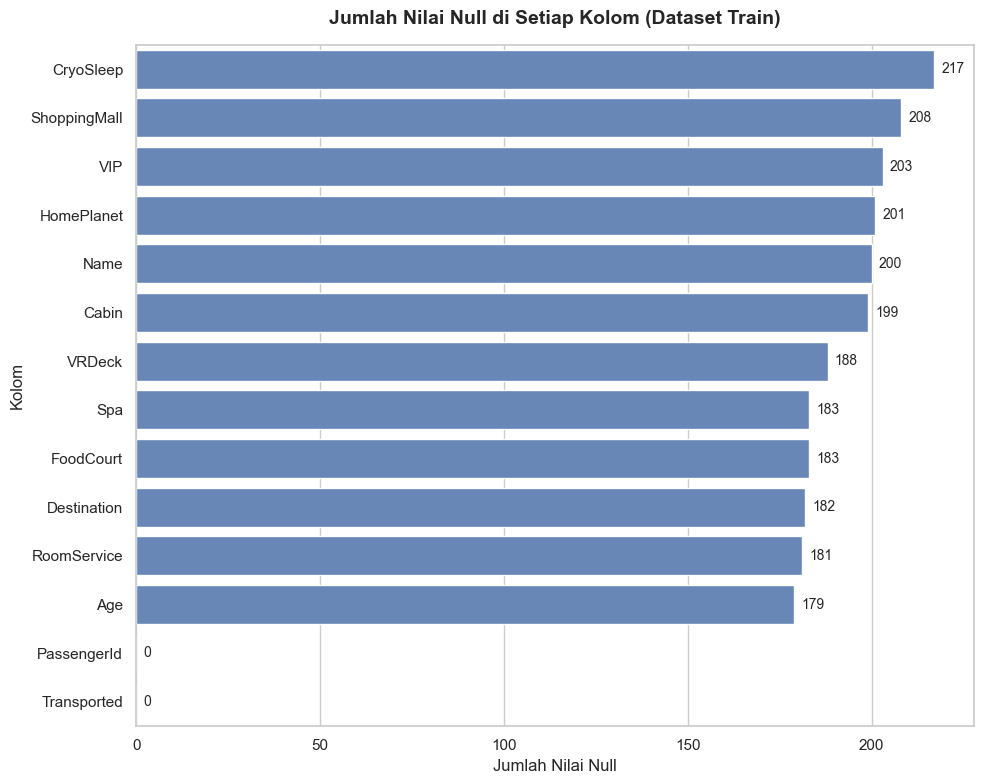

In [5]:
# Jumlah nilai null per kolom, diurutkan menurun
null_values = train.isnull().sum().sort_values(ascending=False)

# Bar chart horizontal
plt.figure(figsize=(10, 8))
sns.barplot(x=null_values.values, y=null_values.index, color='#5b84c4')

plt.title('Jumlah Nilai Null di Setiap Kolom (Dataset Train)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Jumlah Nilai Null', fontsize=12)
plt.ylabel('Kolom', fontsize=12)

# Nilai di sebelah kanan tiap bar
for i, val in enumerate(null_values.values):
    plt.text(val + 2, i, str(val), va='center', ha='left', fontsize=10)

plt.tight_layout()
plt.show()

Temuan: persentase nilai kosong per kolom kecil dan mirip satu sama lain (lihat tabel di atas), dan tidak ada satu kolom yang menonjol. `PassengerId` dan `Transported` lengkap. Pola ini sejalan dengan nilai kosong yang tersebar acak, tetapi hal itu belum diuji secara statistik.

In [6]:
# Baris dengan setidaknya satu nilai null
rows_with_null = train[train.isnull().any(axis=1)]

# Jumlah barisnya
print(f"Jumlah baris yang memiliki setidaknya satu nilai null: {len(rows_with_null)}")

Jumlah baris yang memiliki setidaknya satu nilai null: 2087


In [7]:
# Baris dengan setidaknya satu nilai null
rows_with_null = train[train.isnull().any(axis=1)]

# 5 baris pertama
print("5 Contoh Data dengan Kombinasi Nilai Null:")
display(rows_with_null.head(5))

5 Contoh Data dengan Kombinasi Nilai Null:


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,NaN,Candra Jacostaffey,True
10,0008_02,Europa,True,B/1/P,TRAPPIST-1e,34.0,False,0.0,0.0,NaN,0.0,0.0,Altardr Flatic,True
15,0012_01,Earth,False,NaN,TRAPPIST-1e,31.0,False,32.0,0.0,876.0,0.0,0.0,Justie Pooles,False
16,0014_01,Mars,False,F/3/P,55 Cancri e,27.0,False,1286.0,122.0,NaN,0.0,0.0,Flats Eccle,False
23,0020_03,Earth,True,E/0/S,55 Cancri e,29.0,False,0.0,0.0,NaN,0.0,0.0,Mollen Mcfaddennon,False


## Pola nilai kosong

Sebelum memilih cara imputasi, dicek apakah nilai kosong berkaitan dengan target. Tabel membandingkan rate `Transported` pada baris yang kosong dan yang terisi, dengan uji chi-square per kolom. Karena banyak kolom diuji sekaligus, p-value dibandingkan dengan 0,05 dibagi jumlah kolom (koreksi Bonferroni) agar hubungan kebetulan tidak terlalu mudah dianggap nyata.

In [8]:
kolom_uji = [c for c in train.columns if c not in ("PassengerId", "Transported")]
ambang = 0.05 / len(kolom_uji)

baris = []
for kolom in kolom_uji:
    kosong = train[kolom].isna()
    p_value = chi2_contingency(pd.crosstab(kosong, train["Transported"]))[1]
    baris.append({"kolom": kolom, "n_kosong": int(kosong.sum()),
                  "rate Transported (kosong)": train.loc[kosong, "Transported"].mean(),
                  "rate Transported (terisi)": train.loc[~kosong, "Transported"].mean(),
                  "p-value": p_value, "signifikan (Bonferroni)": bool(p_value < ambang)})
tabel_kosong = pd.DataFrame(baris).set_index("kolom")
print(f"Ambang p-value setelah koreksi Bonferroni: {ambang:.4f}")
display(tabel_kosong)

# Jumlah kolom kosong per baris, dibanding harapan jika kolom saling independen
harapan = np.array([1.0])
for p in train[kolom_uji].isna().mean():
    harapan = np.convolve(harapan, [1 - p, p])
teramati = train[kolom_uji].isna().sum(axis=1).value_counts().sort_index()
perbandingan = pd.DataFrame({"teramati": teramati,
                             "harapan jika independen": (harapan[teramati.index] * len(train)).round(1)})
perbandingan.index.name = "jumlah kolom kosong per baris"
display(perbandingan)

Ambang p-value setelah koreksi Bonferroni: 0.0042


,n_kosong,rate Transported (kosong),rate Transported (terisi),p-value,signifikan (Bonferroni)
kolom,,,,,
HomePlanet,201,0.512438,0.503415,0.855970,False
CryoSleep,217,0.488479,0.504011,0.701632,False
Cabin,199,0.502513,0.503650,1.000000,False
Destination,182,0.505495,0.503584,1.000000,False
Age,179,0.502793,0.503641,1.000000,False
VIP,203,0.512315,0.503416,0.857465,False
RoomService,181,0.458564,0.504582,0.250070,False
FoodCourt,183,0.540984,0.502820,0.343682,False
ShoppingMall,208,0.548077,0.502534,0.219559,False


,teramati,harapan jika independen
jumlah kolom kosong per baris,,
0,6606,6633.6
1,1867,1814.0
2,203,227.3
3,17,17.3


Temuan: tidak ada kolom yang nilai kosongnya berkaitan signifikan dengan target setelah koreksi Bonferroni, dan rate `Transported` pada baris kosong dan terisi hampir sama. Jumlah kolom kosong per baris juga mendekati harapan jika kolom saling independen. Keduanya sejalan dengan nilai kosong yang tersebar acak, dan sejalan dengan hasil eksperimen indikator nilai kosong di fase Modeling yang tidak membantu. Uji ini terbatas pada hubungan dengan target dan antarkolom, jadi bukan bukti mutlak.

## Duplicated Values

In [9]:
train.duplicated(subset='PassengerId').sum()

np.int64(0)

## Data Distribution

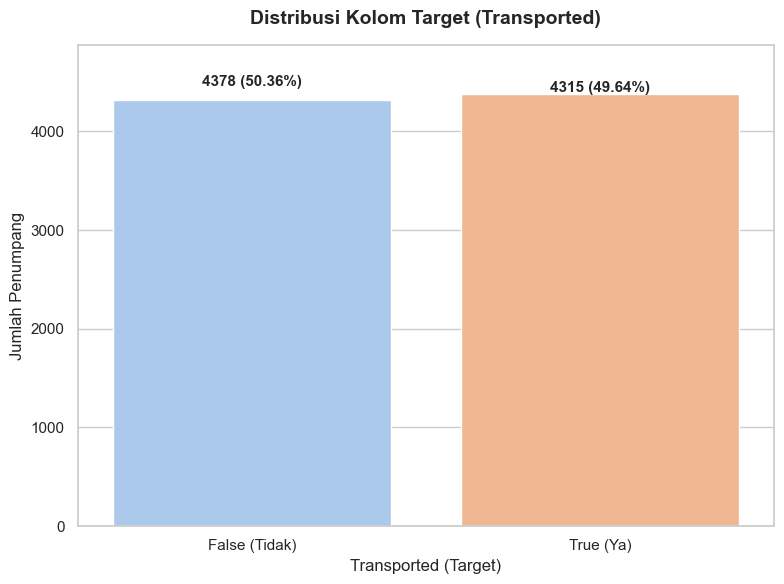

In [10]:
# Distribusi kolom target
target_counts = train['Transported'].value_counts()

# Bar chart dengan warna berbeda tiap batang
plt.figure(figsize=(8, 6))
sns.barplot(x=target_counts.index, y=target_counts.values, hue=target_counts.index, palette='pastel', legend=False)

plt.title('Distribusi Kolom Target (Transported)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Transported (Target)', fontsize=12)
plt.ylabel('Jumlah Penumpang', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['False (Tidak)', 'True (Ya)'])

# Nilai di atas tiap bar
for i, val in enumerate(target_counts.values):
    plt.text(i, val + 50, f"{val} ({val/len(train)*100:.2f}%)", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.ylim(0, max(target_counts.values) + 500)
plt.tight_layout()
plt.show()

Temuan: dua kelas `Transported` hampir seimbang, sehingga accuracy layak menjadi metrik utama dan resampling tidak diperlukan.

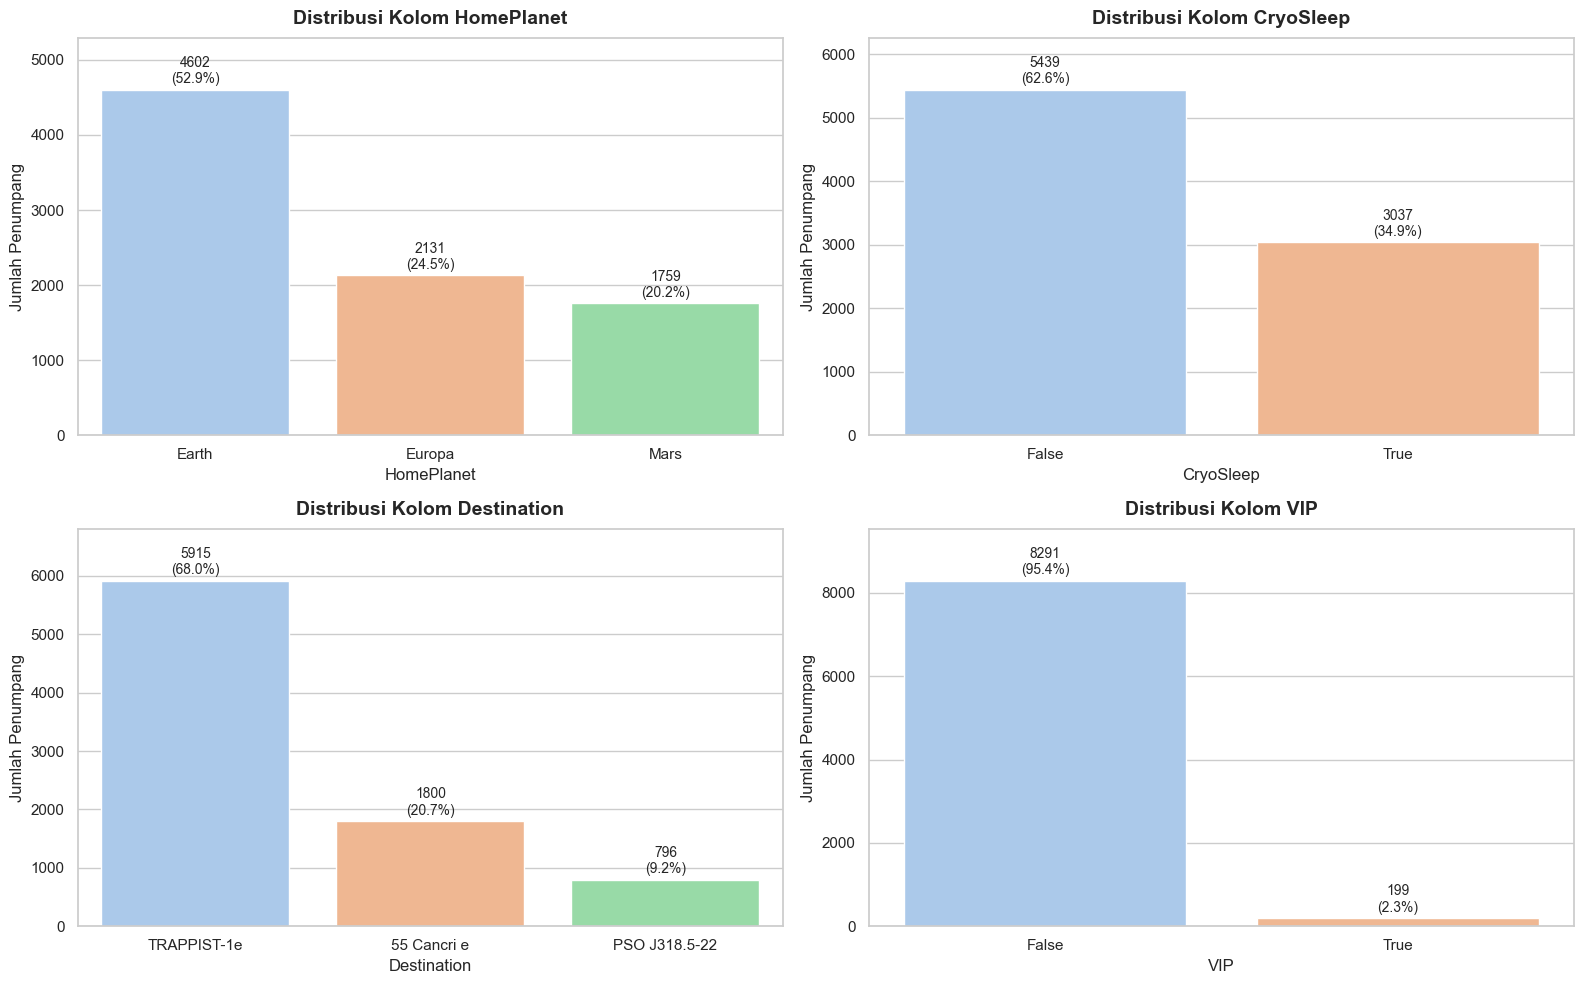

In [11]:
# Kolom kategorikal (tanpa PassengerId, Transported, Name, dan Cabin)
cat_cols = [col for col in train.select_dtypes(include=['object', 'category', 'bool']).columns
            if col not in ['PassengerId', 'Transported', 'Name', 'Cabin']]

# Ukuran grid
n_cols = 2
n_rows = (len(cat_cols) + 1) // n_cols

# Satu grid subplot
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()  # Ratakan array axes

for i, col in enumerate(cat_cols):
    # Frekuensi tiap nilai
    counts = train[col].value_counts(dropna=True)

    sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette='pastel', ax=axes[i], legend=False)

    axes[i].set_title(f'Distribusi Kolom {col}', fontsize=14, fontweight='bold', pad=10)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Jumlah Penumpang', fontsize=12)

    # Label nilai di atas batang
    for j, val in enumerate(counts.values):
        axes[i].text(j, val + (max(counts.values) * 0.01), f"{val}\n({val/len(train)*100:.1f}%)",
                     ha='center', va='bottom', fontsize=10)

    # Margin atas agar label tidak terpotong
    axes[i].set_ylim(0, max(counts.values) * 1.15)

# Hapus axes kosong
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Temuan: `CryoSleep` False lebih banyak daripada True, penumpang Earth paling banyak di `HomePlanet`, dan TRAPPIST-1e paling banyak di `Destination`. `VIP` True jarang dan Deck T sangat jarang, jadi estimasi rate untuk kategori itu kurang stabil. `Side` hampir seimbang.

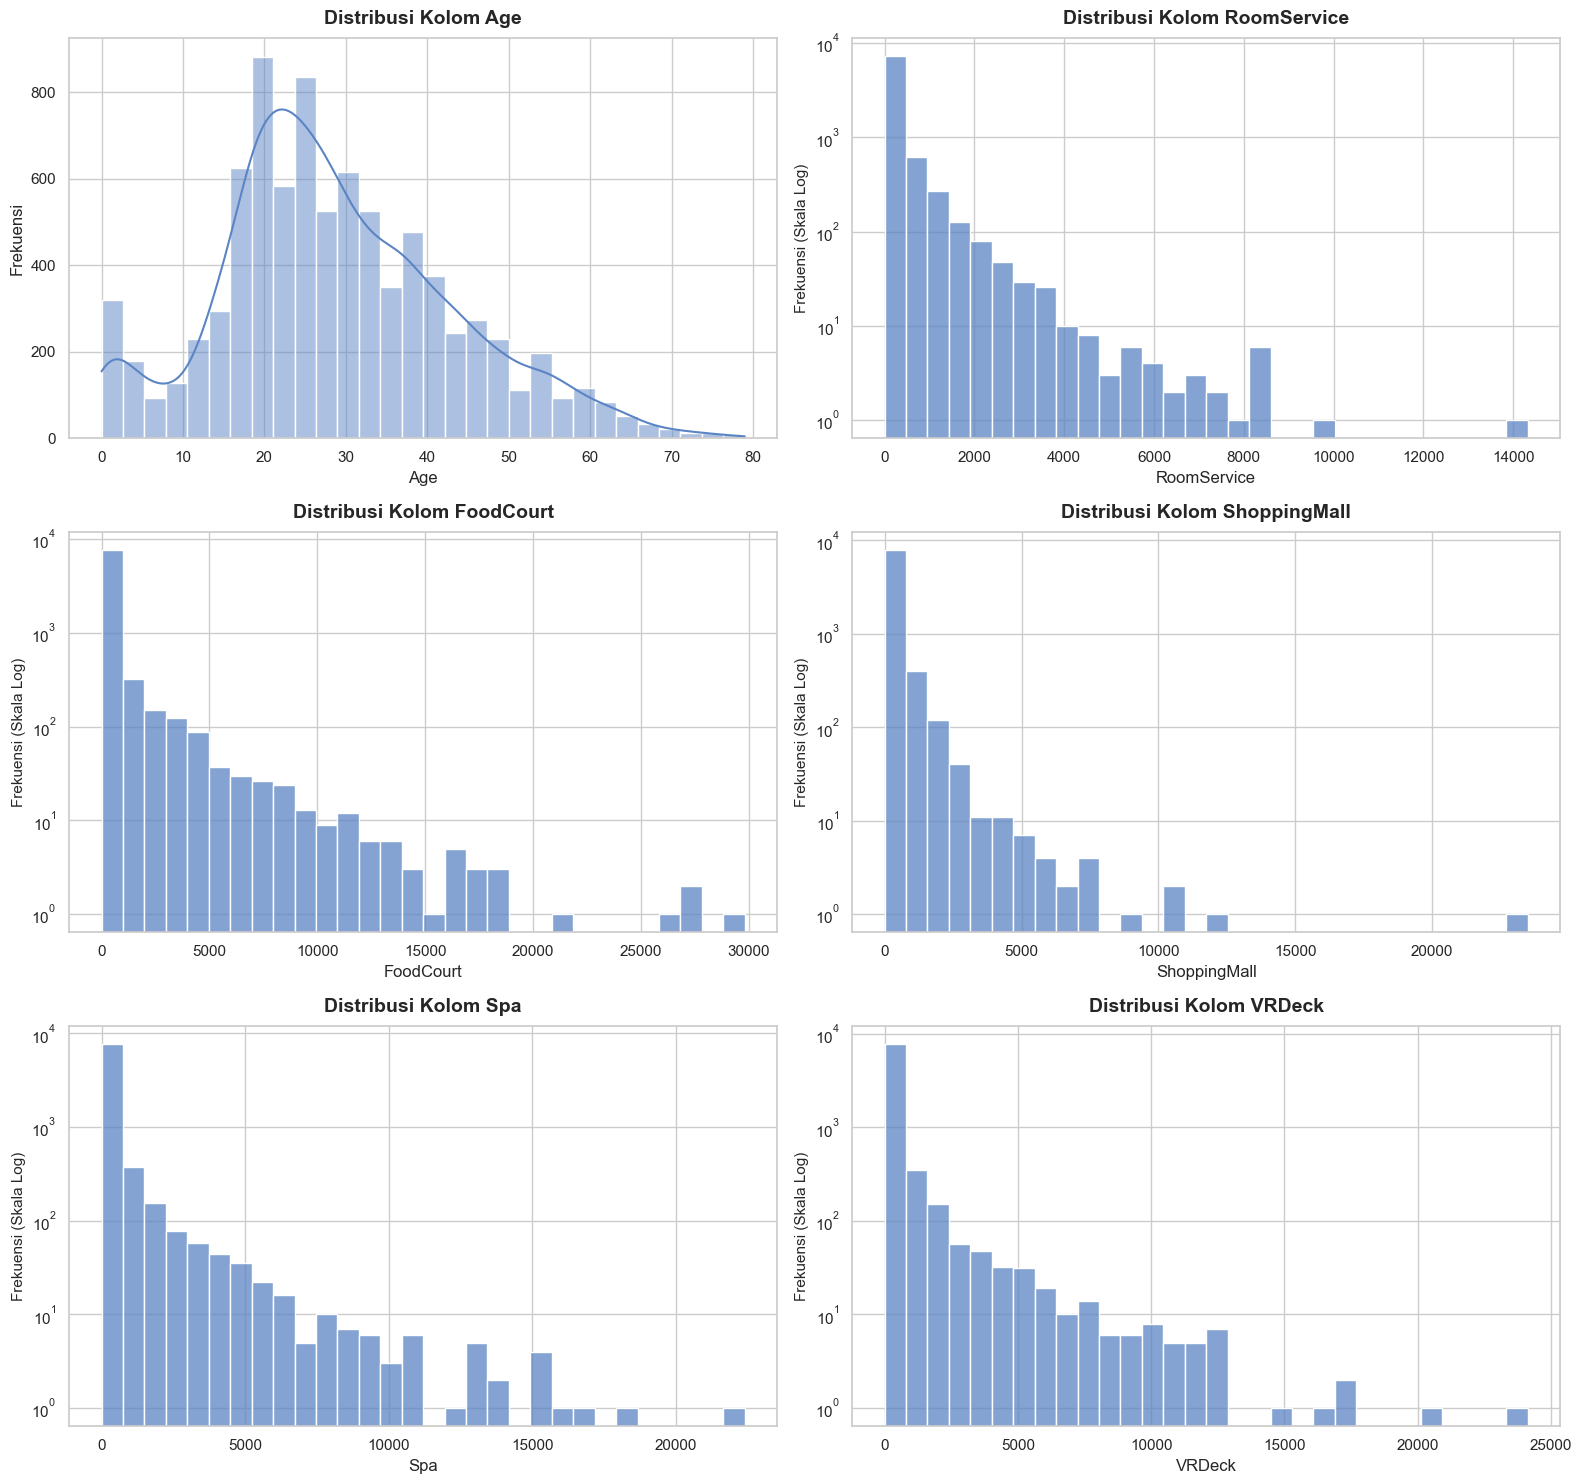

In [12]:
# Kolom numerik
num_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Ukuran grid
n_cols = 2
n_rows = (len(num_cols) + 1) // n_cols

# Satu grid subplot
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()  # Ratakan array axes

for i, col in enumerate(num_cols):
    # Histogram; KDE hanya untuk Age karena KDE tidak bermakna pada sumbu logaritmik
    sns.histplot(data=train, x=col, kde=(col == 'Age'), bins=30, color='#5b84c4', ax=axes[i])

    axes[i].set_title(f'Distribusi Kolom {col}', fontsize=14, fontweight='bold', pad=10)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Frekuensi', fontsize=12)

    # Sumbu Y logaritmik untuk kolom belanja karena sebarannya sangat condong
    if col != 'Age':
        axes[i].set_yscale('log')
        axes[i].set_ylabel('Frekuensi (Skala Log)', fontsize=11)

# Hapus axes kosong
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Temuan: `Age` berpuncak di usia 20-an dengan ekor ke kanan dan ada kelompok kecil di usia anak. Kolom belanja sangat condong: sebagian besar nilai berada di dekat nol dan ekornya panjang, sehingga sumbu Y memakai skala logaritmik dan Pipeline memakai `log1p`.

## Data Logic

In [13]:
SPEND = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]


def tambah_fitur_bantu(df):
    """Pecah PassengerId, Cabin, dan Name menjadi kolom bantu."""
    df = df.copy()
    df["Group"] = df["PassengerId"].str.split("_").str[0]
    cabin = df["Cabin"].str.split("/", expand=True)
    df["Deck"] = cabin[0]
    df["CabinNum"] = pd.to_numeric(cabin[1], errors="coerce")
    df["Side"] = cabin[2]
    df["Surname"] = df["Name"].str.split().str[-1]
    return df


train = tambah_fitur_bantu(train)
test = tambah_fitur_bantu(test)

In [14]:
# Statistik belanja (SPEND) menurut status CryoSleep
spend_by_cryosleep = train.groupby('CryoSleep')[SPEND].agg(['mean', 'median', 'sum'])

print("Analisis Pengeluaran (SPEND) Berdasarkan Status CryoSleep:")
display(spend_by_cryosleep)

Analisis Pengeluaran (SPEND) Berdasarkan Status CryoSleep:


RoomService                     FoodCourt                    \
                 mean median        sum        mean median        sum   
CryoSleep                                                               
False      350.146772    3.0  1865582.0  713.004316    5.0  3799600.0   
True         0.000000    0.0        0.0    0.000000    0.0        0.0   

          ShoppingMall                          Spa                    \
                  mean median        sum       mean median        sum   
CryoSleep                                                               
False       270.586504    2.0  1443579.0  486.09294    7.0  2588931.0   
True          0.000000    0.0        0.0    0.00000    0.0        0.0   

               VRDeck                    
                 mean median        sum  
CryoSleep                                
False      475.716165    4.0  2530810.0  
True         0.000000    0.0        0.0

In [15]:
print("Satu grup -> satu planet     :", (train.groupby('Group')['HomePlanet'].nunique() <= 1).all())
print("Satu keluarga -> satu planet :", (train.groupby('Surname')['HomePlanet'].nunique() <= 1).all())
print("Dek A/B/C/T -> Europa        :", set(train[train['Deck'].isin(list('ABCT'))]['HomePlanet'].dropna()) == {'Europa'})
print("Dek G -> Earth               :", set(train[train['Deck'] == 'G']['HomePlanet'].dropna()) == {'Earth'})
print("Earth -> Tidak VIP           :", ~(train.loc[train['HomePlanet'] == 'Earth', 'VIP'] == True).any())
print("CryoSleep -> belanja 0       :", (train.loc[train['CryoSleep'] == True, SPEND].fillna(0).sum(axis=1) == 0).all())
print("Usia <= 12 -> belanja 0      :", (train.loc[train['Age'] <= 12, SPEND].fillna(0).sum(axis=1) == 0).all())
print("Usia <= 17 -> Tidak VIP      :", ~(train.loc[train['Age'] <= 17, 'VIP'] == True).any())
print("Satu grup -> satu sisi (Side):", (train.groupby('Group')['Side'].nunique() <= 1).all())

Satu grup -> satu planet     : True
Satu keluarga -> satu planet : True
Dek A/B/C/T -> Europa        : True
Dek G -> Earth               : True
Earth -> Tidak VIP           : True
CryoSleep -> belanja 0       : True
Usia <= 12 -> belanja 0      : True
Usia <= 17 -> Tidak VIP      : True
Satu grup -> satu sisi (Side): True


## Outlier dan nilai tidak wajar

Nilai minimum dan maksimum diperiksa untuk mencari nilai mustahil (negatif, usia tidak masuk akal). Karena kolom belanja didominasi nol, kuantil dihitung hanya dari nilai di atas nol.

In [16]:
baris = []
for kolom in ["Age"] + SPEND:
    x = train[kolom].dropna()
    positif = x[x > 0]
    p99 = positif.quantile(0.99)
    atas = train[kolom] > p99
    baris.append({"kolom": kolom, "min": x.min(), "maks": x.max(), "proporsi nol": (x == 0).mean(),
                  "median (>0)": positif.median(), "p95 (>0)": positif.quantile(0.95), "p99 (>0)": p99,
                  "n di atas p99": int(atas.sum()), "rate Transported di atas p99": train.loc[atas, "Transported"].mean()})
tabel_outlier = pd.DataFrame(baris).set_index("kolom")
display(tabel_outlier)

,min,maks,proporsi nol,median (>0),p95 (>0),p99 (>0),n di atas p99,rate Transported di atas p99
kolom,,,,,,,,
Age,0.0,79.0,0.020907,27.0,56.00,65.65,84,0.476190
RoomService,0.0,14327.0,0.655193,320.0,2413.90,4699.28,30,0.000000
FoodCourt,0.0,29813.0,0.641128,396.5,5677.20,12060.04,31,0.774194
ShoppingMall,0.0,23492.0,0.658456,195.0,1872.45,4060.07,29,0.793103
Spa,0.0,22408.0,0.625617,226.5,3936.50,8819.45,32,0.000000
VRDeck,0.0,24133.0,0.646091,260.0,3952.90,9646.26,31,0.000000


Temuan: tidak ada nilai mustahil. Semua nilai tidak negatif, usia berada dalam rentang yang wajar, dan kolom belanja punya ekor kanan panjang dengan sekitar dua pertiga nilai nol. Pembelanja di atas persentil 99 menarik: untuk `RoomService`, `Spa`, dan `VRDeck` tidak ada satu pun yang Transported, sedangkan untuk `FoodCourt` dan `ShoppingMall` kira-kira tiga perempatnya Transported. Jumlahnya hanya sekitar tiga puluh penumpang per kolom, jadi pola ini perlu ditafsirkan hati-hati. Nilai ekstrem tidak dibuang karena tampak valid, bukan salah input.

## Independensi baris (kelompok perjalanan)

Penumpang satu grup bepergian bersama, jadi barisnya mungkin tidak independen. Bila benar, split acak per baris akan memisahkan anggota satu grup ke data latih dan validasi, dan skor validasi menjadi terlalu optimis. Bagian ini memeriksa apakah anggota satu grup cenderung bernasib sama.

In [17]:
irisan = set(train["Group"]) & set(test["Group"])
print("Grup yang muncul di train sekaligus test:", len(irisan))

g = train.groupby("Group")["Transported"].agg(ukuran="size", rata2="mean", nunique="nunique")
print("Jumlah grup train:", len(g), "| grup dengan >1 anggota:", int((g["ukuran"] > 1).sum()),
      "| baris di grup >1 anggota:", int(g.loc[g["ukuran"] > 1, "ukuran"].sum()))

multi = g[g["ukuran"] > 1]
p = train["Transported"].mean()
teramati = (multi["nunique"] == 1).mean()
harapan = (p ** multi["ukuran"] + (1 - p) ** multi["ukuran"]).mean()
print(f"Grup (>1 anggota) dengan target seragam: teramati {teramati:.3f} | harapan jika independen {harapan:.3f}")
print("Teramati lebih tinggi dari harapan independen" if teramati > harapan
      else "Teramati tidak lebih tinggi dari harapan independen")

Grup yang muncul di train sekaligus test: 0
Jumlah grup train: 6217 | grup dengan >1 anggota: 1412 | baris di grup >1 anggota: 3888
Grup (>1 anggota) dengan target seragam: teramati 0.436 | harapan jika independen 0.371
Teramati lebih tinggi dari harapan independen


Tidak ada grup yang muncul di train sekaligus test, jadi fitur tingkat grup seperti `GroupSize` aman dihitung per set. Anggota satu grup cenderung bernasib sama, maka validasi di fase Modeling memakai StratifiedGroupKFold dengan `Group` sebagai kelompok. Dengan begitu satu grup tidak terpecah antara data latih dan validasi.

# 3. Data Preparation

Nilai kosong diisi hanya dengan aturan struktural yang sudah dibuktikan di fase Data Understanding. Imputasi statistik (median/modus) sengaja ditunda ke dalam Pipeline per fold di fase Modeling.

In [18]:
def _isi(df, mask, kolom, nilai, log, nama_aturan):
    """Isi df.loc[mask, kolom] dengan nilai, hanya pada sel yang masih NaN."""
    target = mask & df[kolom].isna()
    if isinstance(nilai, pd.Series):
        target = target & nilai.notna()
        df.loc[target, kolom] = nilai[target]
    else:
        df.loc[target, kolom] = nilai
    n = int(target.sum())
    log[nama_aturan] = log.get(nama_aturan, 0) + n
    return n


def imputasi_struktural(df, referensi=None, max_iter=10):
    """
    df        : DataFrame yang akan diisi (sudah melalui tambah_fitur_bantu).
    referensi : DataFrame tambahan HANYA untuk lookup grup/keluarga
                (misalnya train saat mengisi test). Kolom target tidak dipakai.
    Mengembalikan (df_terisi, log_jumlah_per_aturan).
    """
    df = df.copy()
    # Pastikan kolom boolean bertipe object agar bisa menampung True/False/NaN
    for c in ["CryoSleep", "VIP"]:
        df[c] = df[c].astype(object)

    log = {}
    for _ in range(max_iter):
        berubah = 0
        belanja_ada = df[SPEND].notna().any(axis=1)
        belanja_pos = df[SPEND].fillna(0).sum(axis=1) > 0

        # Aturan 1: ada belanja > 0 -> pasti tidak CryoSleep
        berubah += _isi(df, belanja_pos, "CryoSleep", False, log,
                        "Belanja > 0 -> CryoSleep False")

        # Aturan 2: CryoSleep True -> semua belanja 0
        for c in SPEND:
            berubah += _isi(df, df["CryoSleep"] == True, c, 0.0, log,
                            "CryoSleep True -> belanja 0")

        # Aturan 3: usia <= 12 -> semua belanja 0
        for c in SPEND:
            berubah += _isi(df, df["Age"] <= 12, c, 0.0, log,
                            "Usia <= 12 -> belanja 0")

        # Aturan 4 dan 5: HomePlanet dari grup dan dari nama keluarga
        sumber = df if referensi is None else pd.concat(
            [df, referensi[["Group", "Surname", "HomePlanet"]]], ignore_index=True)
        for kunci, nama in [("Group", "Grup -> HomePlanet"),
                            ("Surname", "Keluarga -> HomePlanet")]:
            peta = (sumber.dropna(subset=[kunci, "HomePlanet"])
                          .groupby(kunci)["HomePlanet"].first())
            berubah += _isi(df, df[kunci].notna(), "HomePlanet",
                            df[kunci].map(peta), log, nama)

        # Aturan 6: dek -> HomePlanet
        berubah += _isi(df, df["Deck"].isin(["A", "B", "C", "T"]), "HomePlanet",
                        "Europa", log, "Dek A/B/C/T -> Europa")
        berubah += _isi(df, df["Deck"] == "G", "HomePlanet", "Earth", log,
                        "Dek G -> Earth")

        # Aturan 7: Earth -> tidak VIP
        berubah += _isi(df, df["HomePlanet"] == "Earth", "VIP", False, log,
                        "Earth -> VIP False")

        # Aturan 8: usia <= 17 -> tidak VIP
        berubah += _isi(df, df["Age"] <= 17, "VIP", False, log,
                        "Usia <= 17 -> VIP False")

        # Aturan 9: satu grup -> satu sisi kabin (terverifikasi di bagian Data Logic)
        peta_sisi = (df.dropna(subset=["Group", "Side"])
                       .groupby("Group")["Side"].first())
        berubah += _isi(df, df["Group"].notna(), "Side",
                        df["Group"].map(peta_sisi), log, "Grup -> Side")

        if berubah == 0:
            break

    for c in ["CryoSleep", "VIP"]:
        df[c] = df[c].map({True: True, False: False})  # NaN tetap NaN
    return df, log

In [19]:
# Simpan jumlah NaN sebelum imputasi untuk perbandingan
nan_sebelum = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})

train, log_train = imputasi_struktural(train)
test, log_tes = imputasi_struktural(test, referensi=train)

nan_sesudah = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})
ringkas = nan_sebelum.join(nan_sesudah, lsuffix="_sebelum", rsuffix="_sesudah")
display(ringkas[(ringkas > 0).any(axis=1)])

print("Jumlah sel terisi per aturan (train):")
display(pd.Series(log_train).sort_values(ascending=False).to_frame("jumlah"))
print("Jumlah sel terisi per aturan (test):")
display(pd.Series(log_tes).sort_values(ascending=False).to_frame("jumlah"))

,train_sebelum,test_sebelum,train_sesudah,test_sesudah
Age,179,91.0,179,91.0
Cabin,199,100.0,199,100.0
CabinNum,199,100.0,199,100.0
CryoSleep,217,93.0,98,38.0
Deck,199,100.0,199,100.0
Destination,182,92.0,182,92.0
FoodCourt,183,106.0,106,65.0
HomePlanet,201,87.0,8,5.0
Name,200,94.0,200,94.0
RoomService,181,82.0,107,55.0


Jumlah sel terisi per aturan (train):


,jumlah
CryoSleep True -> belanja 0,361
Belanja > 0 -> CryoSleep False,119
Earth -> VIP False,117
Grup -> Side,100
Keluarga -> HomePlanet,99
Grup -> HomePlanet,90
Usia <= 12 -> belanja 0,45
Usia <= 17 -> VIP False,12
Dek A/B/C/T -> Europa,2
Dek G -> Earth,2


Jumlah sel terisi per aturan (test):


,jumlah
CryoSleep True -> belanja 0,170
Belanja > 0 -> CryoSleep False,55
Earth -> VIP False,44
Grup -> HomePlanet,41
Keluarga -> HomePlanet,41
Grup -> Side,37
Usia <= 12 -> belanja 0,22
Dek A/B/C/T -> Europa,0
Dek G -> Earth,0
Usia <= 17 -> VIP False,0


In [20]:
# Baris dengan setidaknya satu nilai null
rows_with_null = train[train.isnull().any(axis=1)]

# Jumlah barisnya
print(f"Jumlah baris yang memiliki setidaknya satu nilai null: {len(rows_with_null)}")

Jumlah baris yang memiliki setidaknya satu nilai null: 1384


## Validasi hasil imputasi

Setelah pengisian, aturan struktural dari bagian Data Logic diperiksa lagi agar tetap konsisten.

In [21]:
for nama, d in [("train", train), ("test", test)]:
    print(f"[{nama}]")
    print("  CryoSleep -> belanja 0 :", (d.loc[d["CryoSleep"] == True, SPEND].fillna(0).sum(axis=1) == 0).all())
    print("  Usia <= 12 -> belanja 0:", (d.loc[d["Age"] <= 12, SPEND].fillna(0).sum(axis=1) == 0).all())
    print("  Earth -> Tidak VIP     :", ~(d.loc[d["HomePlanet"] == "Earth", "VIP"] == True).any())
    print("  Usia <= 17 -> Tidak VIP:", ~(d.loc[d["Age"] <= 17, "VIP"] == True).any())

[train]
  CryoSleep -> belanja 0 : True
  Usia <= 12 -> belanja 0: True
  Earth -> Tidak VIP     : True
  Usia <= 17 -> Tidak VIP: True
[test]
  CryoSleep -> belanja 0 : True
  Usia <= 12 -> belanja 0: True
  Earth -> Tidak VIP     : True
  Usia <= 17 -> Tidak VIP: True


## Feature Engineering

Fitur turunan dibuat dengan aturan deterministik (tanpa memakai target dan tanpa statistik yang dipelajari dari data), sehingga aman dihitung sebelum cross-validation.

- `GroupSize`, `IsSolo`: ukuran kelompok perjalanan dari `PassengerId`. Kelompok tidak beririsan antara train dan test (dicek di bagian Independensi baris, fase Data Understanding), jadi dihitung terpisah di tiap set.
- `TotalSpend`: total belanja yang tercatat (batas bawah jika ada kolom belanja yang hilang).
- `NoSpend`: 1 jika kelima belanja diketahui dan nol, 0 jika ada belanja > 0, kosong jika belum bisa dipastikan.
- `CabinRegion`: `CabinNum // 300`, pengelompokan kasar posisi kabin di kapal. Ini hipotesis dari pola kasar pada EDA, bukan aturan pasti, dan diuji di fase Modeling.

Sisa nilai kosong tidak diisi di sini. Imputasi statistiknya dilakukan di dalam Pipeline per fold pada fase Modeling.

In [22]:
def tambah_fitur_turunan(df):
    df = df.copy()
    df["GroupSize"] = df.groupby("Group")["PassengerId"].transform("size")
    df["IsSolo"] = (df["GroupSize"] == 1).astype(int)
    df["TotalSpend"] = df[SPEND].sum(axis=1, min_count=1)
    semua_ada = df[SPEND].notna().all(axis=1)
    ada_belanja = (df[SPEND].fillna(0) > 0).any(axis=1)
    df["NoSpend"] = np.where(ada_belanja, 0.0, np.where(semua_ada, 1.0, np.nan))
    df["CabinRegion"] = df["CabinNum"] // 300
    return df


train = tambah_fitur_turunan(train)
test = tambah_fitur_turunan(test)

display(train[["PassengerId", "GroupSize", "IsSolo", "TotalSpend", "NoSpend", "CabinRegion"]].head())
print("NaN fitur baru (train):")
print(train[["GroupSize", "IsSolo", "TotalSpend", "NoSpend", "CabinRegion"]].isna().sum())

,PassengerId,GroupSize,IsSolo,TotalSpend,NoSpend,CabinRegion
0,0001_01,1,1,0.0,1.0,0.0
1,0002_01,1,1,736.0,0.0,0.0
2,0003_01,2,0,10383.0,0.0,0.0
3,0003_02,2,0,5176.0,0.0,0.0
4,0004_01,1,1,1091.0,0.0,0.0


NaN fitur baru (train):
GroupSize        0
IsSolo           0
TotalSpend       0
NoSpend         16
CabinRegion    199
dtype: int64


## Eksplorasi lanjutan terhadap target

Grafik menunjukkan persentase `Transported = True` pada tiap kategori, dengan garis putus-putus sebagai rata-rata keseluruhan. Hubungan yang terlihat bersifat asosiatif; data ini tidak membuktikan sebab-akibat. Nilai `nan` adalah baris yang masih kosong setelah imputasi struktural.

Bagian ini berada setelah Feature Engineering karena memakai data yang sudah diisi dan fitur turunan. Secara konsep ia melanjutkan fase Data Understanding, karena CRISP-DM bersifat iteratif.

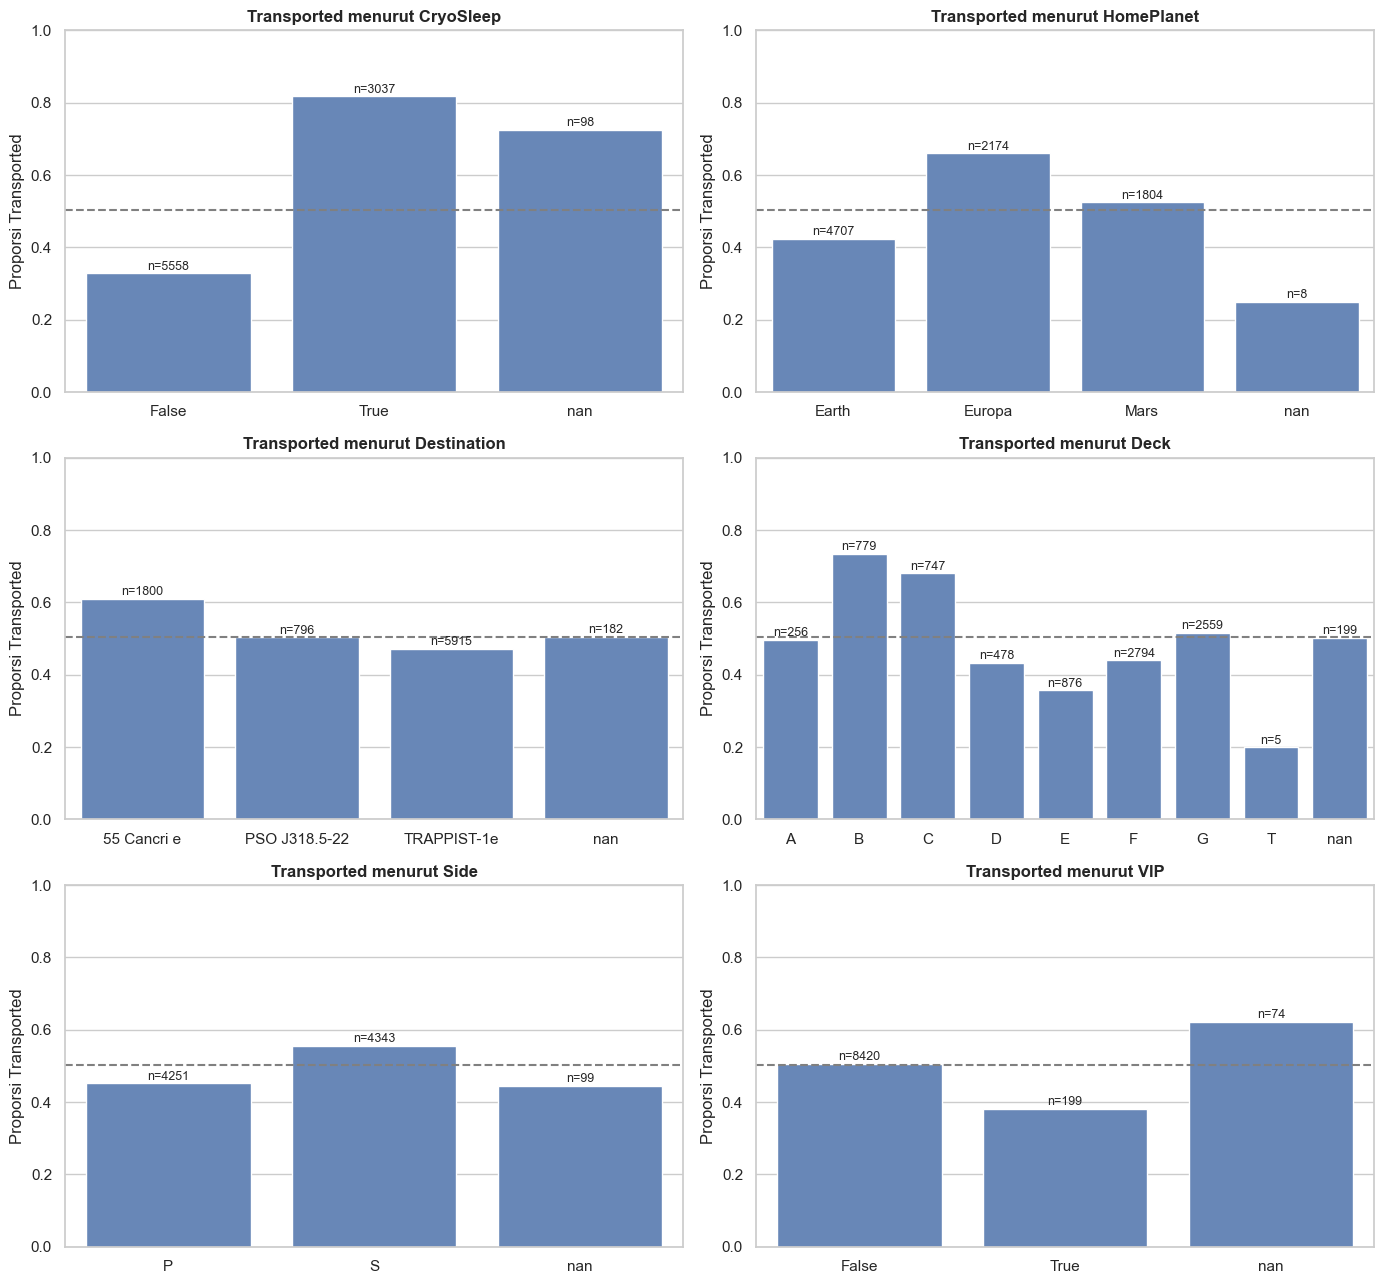

In [23]:
def plot_rate(ax, x, y, judul):
    d = (pd.DataFrame({"x": x.astype(str), "y": y.astype(float)})
           .groupby("x")["y"].agg(["mean", "size"]).reset_index())
    sns.barplot(data=d, x="x", y="mean", color="#5b84c4", ax=ax)
    ax.axhline(y.mean(), ls="--", color="gray")
    for i, r in d.iterrows():
        ax.text(i, r["mean"] + 0.01, f"n={int(r['size'])}", ha="center", fontsize=9)
    ax.set_title(judul, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Proporsi Transported")
    ax.set_ylim(0, 1)


target_eda = train["Transported"]
fig, axes = plt.subplots(3, 2, figsize=(14, 13))
for ax, col in zip(axes.flatten(), ["CryoSleep", "HomePlanet", "Destination", "Deck", "Side", "VIP"]):
    plot_rate(ax, train[col], target_eda, f"Transported menurut {col}")
plt.tight_layout()
plt.show()

Temuan: penumpang `CryoSleep` True jauh lebih sering Transported daripada False. Penumpang Europa lebih sering Transported daripada Earth, dengan Mars di antaranya, dan Deck B dan C tinggi sedangkan Deck E rendah. Sisi S lebih tinggi daripada P, tujuan 55 Cancri e lebih tinggi daripada TRAPPIST-1e, dan penumpang VIP lebih rendah.

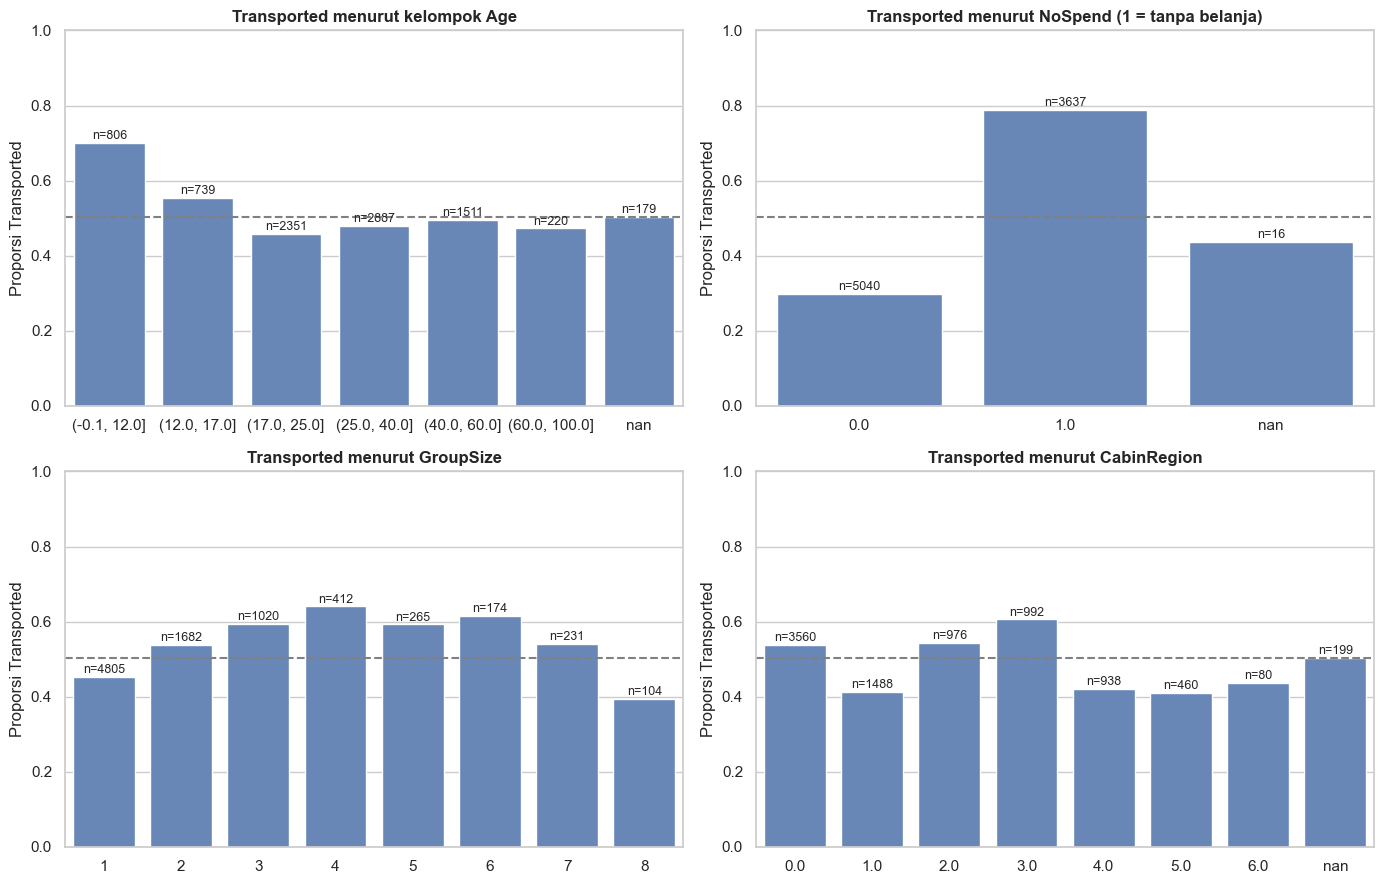

In [24]:
kelompok_usia = pd.cut(train["Age"], [-0.1, 12, 17, 25, 40, 60, 100])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_rate(axes[0, 0], kelompok_usia, target_eda, "Transported menurut kelompok Age")
plot_rate(axes[0, 1], train["NoSpend"], target_eda, "Transported menurut NoSpend (1 = tanpa belanja)")
plot_rate(axes[1, 0], train["GroupSize"], target_eda, "Transported menurut GroupSize")
plot_rate(axes[1, 1], train["CabinRegion"], target_eda, "Transported menurut CabinRegion")
plt.tight_layout()
plt.show()

Temuan: anak-anak (usia sampai 12 tahun) paling sering Transported dan kelompok 18 sampai 25 tahun paling jarang. Penumpang tanpa belanja jauh lebih sering Transported. Rate naik bersama ukuran grup sampai ukuran 4, lalu tidak beraturan dan terendah pada ukuran 8; grup besar jumlahnya sedikit. `CabinRegion` bervariasi tanpa pola naik atau turun yang jelas.

In [25]:
def ringkas_rate(x, nama, n_min=100):
    d = (pd.DataFrame({"x": x.astype(str), "y": target_eda.astype(float)})
           .groupby("x")["y"].agg(["mean", "size"]))
    d = d[(d["size"] >= n_min) & (d.index != "nan")]
    return {"fitur": nama,
            "kategori tertinggi": d["mean"].idxmax(), "rate tertinggi": d["mean"].max(),
            "kategori terendah": d["mean"].idxmin(), "rate terendah": d["mean"].min(),
            "selisih": d["mean"].max() - d["mean"].min()}


fitur_eda = {col: train[col] for col in ["CryoSleep", "HomePlanet", "Destination", "Deck", "Side", "VIP"]}
fitur_eda.update({"kelompok Age": kelompok_usia, "NoSpend": train["NoSpend"],
                  "GroupSize": train["GroupSize"], "CabinRegion": train["CabinRegion"]})
ringkasan_rate = (pd.DataFrame([ringkas_rate(x, nama) for nama, x in fitur_eda.items()])
                    .sort_values("selisih", ascending=False).reset_index(drop=True))
print("Kategori dengan n < 100 dan nilai kosong tidak dihitung.")
display(ringkasan_rate)

Kategori dengan n < 100 dan nilai kosong tidak dihitung.


,fitur,kategori tertinggi,rate tertinggi,kategori terendah,rate terendah,selisih
0,CryoSleep,True,0.817583,False,0.328176,0.489408
1,NoSpend,1.0,0.788012,0.0,0.298611,0.489401
2,Deck,B,0.734275,E,0.357306,0.376969
3,GroupSize,4,0.640777,8,0.394231,0.246546
4,kelompok Age,"(-0.1, 12.0]",0.699752,"(17.0, 25.0]",0.458103,0.241649
5,HomePlanet,Europa,0.660534,Earth,0.423624,0.236909
6,CabinRegion,3.0,0.605847,5.0,0.410870,0.194977
7,Destination,55 Cancri e,0.610000,TRAPPIST-1e,0.471175,0.138825
8,VIP,False,0.505463,True,0.381910,0.123554
9,Side,S,0.555607,P,0.451894,0.103713


Tabel menyusun fitur dari perbedaan rate terbesar. `CryoSleep` dan `NoSpend` paling kuat dengan selisih hampir sama, karena keduanya terkait (penumpang yang tidur beku tidak berbelanja). Berikutnya `Deck`, ukuran grup, usia, dan `HomePlanet`; `VIP` dan `Side` paling lemah. Perbedaan ini asosiatif, dan beberapa fitur saling berkorelasi (`Deck` dengan `HomePlanet`, `CryoSleep` dengan `NoSpend`), jadi tabel ini tidak menunjukkan kontribusi independen tiap fitur.

## Korelasi dan mutual information

Korelasi Spearman menunjukkan fitur numerik yang saling berkaitan. Mutual information (dalam nat) mengukur seberapa besar informasi tiap fitur tentang target, termasuk hubungan non-linear. Nilainya dihitung per fitur pada baris yang terisi, tanpa imputasi, karena ini eksplorasi deskriptif dan bukan evaluasi model.

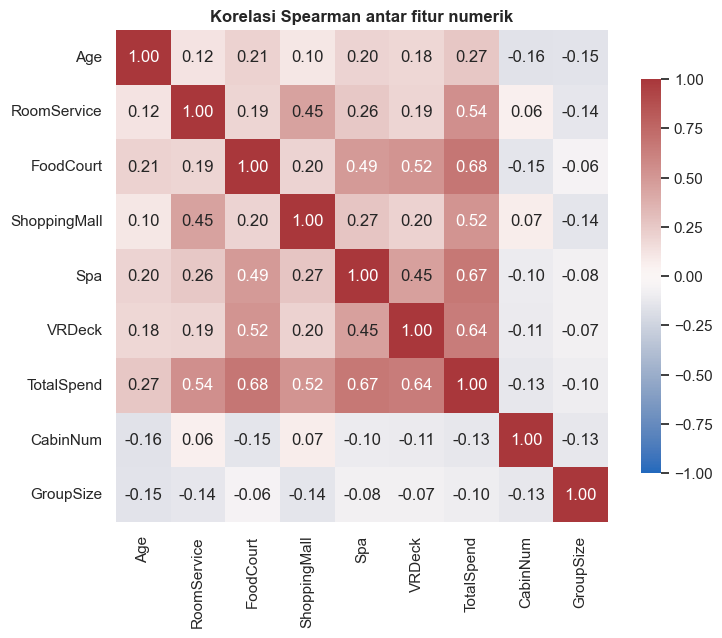

,fitur,mutual_information,n
0,TotalSpend,0.136525,8693
1,NoSpend,0.122461,8677
2,CryoSleep,0.116038,8595
3,RoomService,0.079542,8586
4,Spa,0.077028,8579
5,VRDeck,0.069395,8586
6,ShoppingMall,0.054642,8590
7,FoodCourt,0.047821,8587
8,Deck,0.023700,8494
9,GroupSize,0.020903,8693


In [26]:
fitur_num = ["Age"] + SPEND + ["TotalSpend", "CabinNum", "GroupSize"]
plt.figure(figsize=(8, 6.5))
sns.heatmap(train[fitur_num].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag",
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8})
plt.title("Korelasi Spearman antar fitur numerik", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

diskrit = ["HomePlanet", "CryoSleep", "Destination", "Deck", "Side", "VIP", "IsSolo", "NoSpend", "CabinRegion"]
baris = []
for kolom in diskrit + fitur_num:
    ada = train[kolom].notna()
    x = train.loc[ada, kolom]
    if kolom in diskrit:
        x = pd.Series(pd.factorize(x)[0], index=x.index)
    mi = mutual_info_classif(x.to_numpy(dtype=float).reshape(-1, 1), target_eda[ada].astype(int),
                             discrete_features=(kolom in diskrit), random_state=SEED)[0]
    baris.append({"fitur": kolom, "mutual_information": mi, "n": int(ada.sum())})
tabel_mi = pd.DataFrame(baris).sort_values("mutual_information", ascending=False).reset_index(drop=True)
display(tabel_mi)

Temuan: kolom belanja saling berkorelasi positif tingkat sedang, dan `TotalSpend` berkorelasi paling kuat dengan tiap kolom belanja karena ia adalah jumlahnya. `Age` dan `GroupSize` berkorelasi lemah dengan fitur lain. Menurut mutual information, `TotalSpend`, `NoSpend`, dan `CryoSleep` paling informatif tentang target, disusul kolom belanja individual. `Deck`, `GroupSize`, `HomePlanet`, dan `CabinNum` jauh lebih lemah, dan `Side`, `Destination`, serta `VIP` hampir tidak informatif sendirian. Mutual information menilai satu fitur sekali waktu, jadi fitur yang lemah sendirian masih bisa berguna dalam interaksi.

## Simpan dataset bersih

`Name`, `Surname`, dan `Cabin` dibuang; `Cabin` sudah diuraikan menjadi `Deck`, `CabinNum`, dan `Side`. `Group` dipertahankan sebagai kunci validasi per grup.

In [27]:
KOLOM_BERSIH = (["PassengerId", "Group", "HomePlanet", "CryoSleep", "Destination", "Age", "VIP"]
                + SPEND
                + ["Deck", "CabinNum", "Side", "CabinRegion", "GroupSize", "IsSolo", "TotalSpend", "NoSpend"])

train_clean = train[KOLOM_BERSIH + ["Transported"]]
test_clean = test[KOLOM_BERSIH]

# Cek konsistensi sebelum menyimpan
assert (test_clean["PassengerId"].values == sample["PassengerId"].values).all(), "Urutan test berbeda dari sample_submission"
assert train_clean["PassengerId"].is_unique and test_clean["PassengerId"].is_unique
assert list(test_clean.columns) == KOLOM_BERSIH

CLEAN_DIR = Path("data/clean")
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
train_clean.to_csv(CLEAN_DIR / "train_clean.csv", index=False)
test_clean.to_csv(CLEAN_DIR / "test_clean.csv", index=False)

# Verifikasi dengan membaca ulang dari file
cek_train = pd.read_csv(CLEAN_DIR / "train_clean.csv")
cek_test = pd.read_csv(CLEAN_DIR / "test_clean.csv")
print("Bentuk train_clean:", cek_train.shape, "| test_clean:", cek_test.shape)
print("Distribusi target (train_clean):")
print(cek_train["Transported"].value_counts(normalize=True).round(4))
print("Sisa NaN per kolom (train_clean | test_clean):")
nan_akhir = pd.DataFrame({"train_clean": cek_train.isna().sum(), "test_clean": cek_test.isna().sum()})
display(nan_akhir[(nan_akhir > 0).any(axis=1)])

Bentuk train_clean: (8693, 21) | test_clean: (4277, 20)
Distribusi target (train_clean):
Transported
True     0.5036
False    0.4964
Name: proportion, dtype: float64
Sisa NaN per kolom (train_clean | test_clean):


,train_clean,test_clean
Age,179,91.0
CabinNum,199,100.0
CabinRegion,199,100.0
CryoSleep,98,38.0
Deck,199,100.0
Destination,182,92.0
FoodCourt,106,65.0
HomePlanet,8,5.0
NoSpend,16,5.0
RoomService,107,55.0


# 4. Modeling

Mulai bagian ini `data_latih` berisi dataset bersih (`train_clean`, sama dengan `data/clean/train_clean.csv`), dan `data_uji` berisi padanannya untuk data uji. `CryoSleep` dan `VIP` diubah menjadi 1.0/0.0/NaN agar bisa masuk Pipeline.

In [28]:
data_latih = train_clean.copy()
data_uji = test_clean.copy()

for kolom in ["CryoSleep", "VIP"]:
    data_latih[kolom] = data_latih[kolom].map({True: 1.0, False: 0.0})
    data_uji[kolom] = data_uji[kolom].map({True: 1.0, False: 0.0})

# Group dipakai hanya sebagai kunci kelompok CV, bukan fitur
y = data_latih["Transported"].astype(int)
groups = data_latih["Group"]

print("Bentuk data_latih:", data_latih.shape, "| data_uji:", data_uji.shape)
print("Distribusi target:")
print(y.value_counts(normalize=True).round(4))
print("Jumlah grup:", groups.nunique())

Bentuk data_latih: (8693, 21) | data_uji: (4277, 20)
Distribusi target:
Transported
1    0.5036
0    0.4964
Name: proportion, dtype: float64
Jumlah grup: 6217


## Preprocessing dan pipeline

Kolom dibagi tiga jenis. Semua imputasi memakai statistik data latih per fold.

| Jenis | Kolom | Perlakuan |
|---|---|---|
| Kategorikal | `HomePlanet`, `Destination`, `Deck`, `Side` | imputasi modus, lalu one-hot |
| Biner | `CryoSleep`, `VIP`, `IsSolo`, `NoSpend` | imputasi modus |
| Numerik | `Age`, `CabinNum`, `CabinRegion`, `GroupSize`, `TotalSpend`, lima kolom belanja | imputasi median, `log1p` (belanja sangat condong ke kanan), scaling khusus Logistic Regression |

Catatan: `TotalSpend` dan `NoSpend` dihitung di fase Data Preparation dari belanja yang tercatat. Keduanya tidak dihitung ulang setelah imputasi di sini; ini penyederhanaan.

In [29]:
KAT = ["HomePlanet", "Destination", "Deck", "Side"]
BINER = ["CryoSleep", "VIP", "IsSolo", "NoSpend"]
NUM = ["Age", "CabinNum", "CabinRegion", "GroupSize", "TotalSpend"] + SPEND
SEMUA = KAT + BINER + NUM

X = data_latih[SEMUA]


def buat_pipeline(model, skala=False, buang=(), tambahan=(), indikator=False):
    """Pipeline lengkap: preprocessing + model.
    `buang` = kolom yang dikeluarkan (ablation), `tambahan` = kolom numerik tambahan (eksperimen fitur),
    `indikator` = tambahkan penanda nilai kosong pada imputer."""
    kat = [c for c in KAT if c not in buang]
    biner = [c for c in BINER if c not in buang]
    num = [c for c in NUM if c not in buang] + list(tambahan)

    langkah_num = [("imputer", SimpleImputer(strategy="median", add_indicator=indikator)),
                   ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))]
    if skala:
        langkah_num.append(("scaler", StandardScaler()))

    pre = ColumnTransformer([
        ("kat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), kat),
        ("biner", SimpleImputer(strategy="most_frequent", add_indicator=indikator), biner),
        ("num", Pipeline(langkah_num), num),
    ])
    return Pipeline([("pre", pre), ("m", model)])


def model_dasar(nama):
    if nama == "Dummy (baseline)":
        return DummyClassifier(strategy="prior")
    if nama == "Logistic Regression":
        return LogisticRegression(max_iter=2000, random_state=SEED)
    if nama == "Random Forest":
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=1, random_state=SEED)
    if nama == "HistGradientBoosting":
        return HistGradientBoostingClassifier(random_state=SEED)
    if nama == "XGBoost":
        return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                             tree_method="hist", n_jobs=1, random_state=SEED, verbosity=0)
    if nama == "CatBoost":
        return CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, thread_count=1,
                                  random_seed=SEED, verbose=0, allow_writing_files=False)
    if nama == "Ensemble (soft voting)":
        anggota = [("hgb", "HistGradientBoosting"), ("rf", "Random Forest"), ("xgb", "XGBoost"), ("cat", "CatBoost")]
        return VotingClassifier([(k, model_dasar(n)) for k, n in anggota], voting="soft")
    raise ValueError(nama)


def pipeline_model(nama, buang=()):
    return buat_pipeline(model_dasar(nama), skala=(nama == "Logistic Regression"), buang=buang)


NAMA_MODEL = ["Dummy (baseline)", "Logistic Regression", "Random Forest", "HistGradientBoosting",
              "XGBoost", "CatBoost", "Ensemble (soft voting)"]


## Pemeriksaan pergeseran data (adversarial validation)

Sebuah model dilatih untuk membedakan baris data latih dari baris data uji. Jika data uji berasal dari sebaran yang sama dengan data latih, model tidak bisa membedakannya dan AUC mendekati 0,5. AUC yang tinggi berarti ada pergeseran, dan skor validasi tidak bisa dipercaya untuk data uji. Pembagian fold memakai `Group`, seperti validasi lainnya.

In [30]:
X_gabung = pd.concat([data_latih[SEMUA], data_uji[SEMUA]], ignore_index=True)
asal_data = np.r_[np.zeros(len(data_latih)), np.ones(len(data_uji))].astype(int)
grup_gabung = pd.concat([data_latih["Group"], data_uji["Group"]], ignore_index=True)

r_adv = cross_validate(pipeline_model("HistGradientBoosting"), X_gabung, asal_data, groups=grup_gabung,
                       cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED),
                       scoring="roc_auc", n_jobs=-1)
print(f"AUC pembeda data latih vs data uji: {r_adv['test_score'].mean():.3f} ± {r_adv['test_score'].std():.3f}"
      " (0,5 = tidak bisa dibedakan)")

AUC pembeda data latih vs data uji: 0.487 ± 0.018 (0,5 = tidak bisa dibedakan)


Temuan: model tidak bisa membedakan data latih dari data uji (AUC tidak lebih dari tingkat kebetulan), jadi tidak ada tanda pergeseran sebaran fitur antara keduanya. Asumsi bahwa data latih mewakili data uji tidak terbantah. Pemeriksaan ini tidak menjamin skor leaderboard sama dengan skor validasi.

## Baseline dan perbandingan model

Tiap model dievaluasi dengan 5-fold StratifiedGroupKFold yang diulang dengan 3 seed berbeda (15 skor per model). Semua model memakai pembagian fold yang sama.

In [31]:
SKOR = ["accuracy", "roc_auc", "f1"]
SEEDS = [SEED, SEED + 1, SEED + 2]


def evaluasi_cv(model, X_in=None, seeds=SEEDS):
    """Mengembalikan DataFrame skor per fold (seed x fold)."""
    X_in = X if X_in is None else X_in
    baris = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
        r = cross_validate(model, X_in, y, groups=groups, cv=cv, scoring=SKOR, n_jobs=-1)
        for k in range(5):
            baris.append({"seed": s, "fold": k, **{m: r[f"test_{m}"][k] for m in SKOR}})
    return pd.DataFrame(baris)


def ringkas(df_skor):
    return {m: f"{df_skor[m].mean():.4f} ± {df_skor[m].std():.4f}" for m in SKOR}


hasil_default = {nama: evaluasi_cv(pipeline_model(nama)) for nama in NAMA_MODEL}

tabel = pd.DataFrame({nama: ringkas(df) for nama, df in hasil_default.items()}).T
tabel["accuracy_min-max"] = [f"{df['accuracy'].min():.3f}-{df['accuracy'].max():.3f}"
                             for df in hasil_default.values()]
display(tabel)

,accuracy,roc_auc,f1,accuracy_min-max
Dummy (baseline),0.4981 ± 0.0113,0.5000 ± 0.0000,0.5784 ± 0.2350,0.477-0.514
Logistic Regression,0.7759 ± 0.0123,0.8538 ± 0.0138,0.7808 ± 0.0132,0.754-0.802
Random Forest,0.8023 ± 0.0113,0.8950 ± 0.0090,0.7994 ± 0.0116,0.783-0.816
HistGradientBoosting,0.8086 ± 0.0112,0.9022 ± 0.0088,0.8100 ± 0.0099,0.792-0.823
XGBoost,0.8093 ± 0.0104,0.9023 ± 0.0091,0.8111 ± 0.0097,0.788-0.824
CatBoost,0.8147 ± 0.0106,0.9069 ± 0.0089,0.8165 ± 0.0101,0.796-0.832
Ensemble (soft voting),0.8118 ± 0.0120,0.9053 ± 0.0089,0.8130 ± 0.0112,0.789-0.829


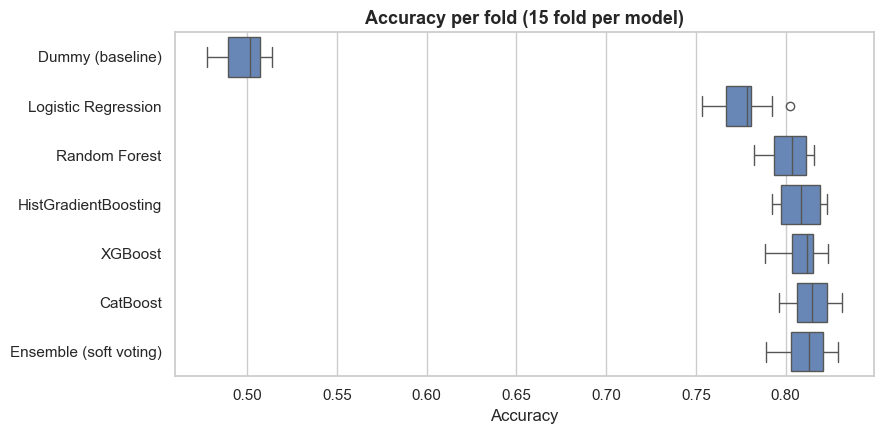

In [32]:
gabung = pd.concat([df.assign(model=nama) for nama, df in hasil_default.items()])
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=gabung, x="accuracy", y="model", color="#5b84c4")
plt.title("Accuracy per fold (15 fold per model)", fontsize=13, fontweight="bold")
plt.xlabel("Accuracy")
plt.ylabel("")
plt.tight_layout()
plt.show()

Selisih tiap model terhadap Logistic Regression dihitung per fold (fold-nya sama), sehingga perbedaan kecil bisa dibandingkan dengan sebarannya.

In [33]:
acuan = hasil_default["Logistic Regression"]["accuracy"].values
selisih = {nama: df["accuracy"].values - acuan
           for nama, df in hasil_default.items() if nama != "Logistic Regression"}
tabel_selisih = pd.DataFrame({
    nama: {"rata-rata selisih": d.mean(), "simpangan baku": d.std(),
           "fold lebih baik": f"{(d > 0).sum()}/{len(d)}"}
    for nama, d in selisih.items()}).T
display(tabel_selisih)

d_cb = hasil_default["CatBoost"]["accuracy"].values - hasil_default["HistGradientBoosting"]["accuracy"].values
print(f"CatBoost dibanding HistGradientBoosting: selisih rata-rata {d_cb.mean():.4f} "
      f"(simpangan baku {d_cb.std():.4f}), lebih baik di {(d_cb > 0).sum()}/{len(d_cb)} fold")

,rata-rata selisih,simpangan baku,fold lebih baik
Dummy (baseline),-0.277879,0.017657,0/15
Random Forest,0.026353,0.007512,15/15
HistGradientBoosting,0.032616,0.008173,15/15
XGBoost,0.033394,0.008724,15/15
CatBoost,0.038803,0.006723,15/15
Ensemble (soft voting),0.035863,0.007862,15/15


CatBoost dibanding HistGradientBoosting: selisih rata-rata 0.0062 (simpangan baku 0.0036), lebih baik di 14/15 fold


Temuan: semua model berbasis pohon dan boosting jauh di atas Logistic Regression dan lebih baik di semua 15 fold. CatBoost default paling tinggi, dan lebih baik dari HistGradientBoosting pada sebagian besar fold (lihat baris di bawah tabel). HistGradientBoosting dan XGBoost hampir sama, dan ensemble rata-rata probabilitas tidak melampaui CatBoost sendiri.

## Ablation fitur

Fase Data Preparation menghasilkan dua hipotesis: fitur grup (`GroupSize`, `IsSolo`) dan `CabinRegion` berguna bagi model. Di sini setiap kelompok fitur dicabut satu per satu dari HistGradientBoosting (default), lalu skornya diukur ulang.

In [34]:
skenario = {
    "Semua fitur": (),
    "Tanpa CabinRegion": ("CabinRegion",),
    "Tanpa fitur grup (GroupSize, IsSolo)": ("GroupSize", "IsSolo"),
    "Tanpa TotalSpend dan NoSpend": ("TotalSpend", "NoSpend"),
    "Tanpa Deck, CabinNum, CabinRegion, Side": ("Deck", "CabinNum", "CabinRegion", "Side"),
}
hasil_ablation = {}
for nama, buang in skenario.items():
    hasil_ablation[nama] = evaluasi_cv(pipeline_model("HistGradientBoosting", buang=buang), X_in=data_latih[SEMUA])

semua = hasil_ablation["Semua fitur"]["accuracy"].values
tabel_abl = pd.DataFrame({
    nama: {"accuracy": f"{df['accuracy'].mean():.4f} ± {df['accuracy'].std():.4f}",
           "selisih vs semua fitur": (df["accuracy"].values - semua).mean(),
           "fold lebih baik dari semua fitur": f"{(df['accuracy'].values > semua).sum()}/{len(df)}"}
    for nama, df in hasil_ablation.items()}).T
display(tabel_abl)

,accuracy,selisih vs semua fitur,fold lebih baik dari semua fitur
Semua fitur,0.8086 ± 0.0112,0.0,0/15
Tanpa CabinRegion,0.8102 ± 0.0098,0.001679,9/15
"Tanpa fitur grup (GroupSize, IsSolo)",0.8083 ± 0.0122,-0.000288,6/15
Tanpa TotalSpend dan NoSpend,0.8077 ± 0.0121,-0.000863,7/15
"Tanpa Deck, CabinNum, CabinRegion, Side",0.7931 ± 0.0141,-0.015449,0/15


Jika selisih ablation lebih kecil daripada simpangan baku antar fold, fitur tersebut tidak terbukti membantu.

## Eksperimen fitur tambahan

Beberapa ide fitur diuji satu per satu pada HistGradientBoosting default, dengan 15 fold yang sama seperti ablation:

- `FamilySize`: jumlah penumpang dengan nama belakang sama.
- `CabinShare`: jumlah penumpang yang memakai kabin yang sama.
- Fitur agregat grup: proporsi anggota grup yang tidur beku, rata-rata total belanja grup, dan proporsi anggota tanpa belanja.
- `JumlahKosong`: banyaknya kolom yang masih kosong pada tiap baris.
- Indikator nilai kosong pada imputer (`add_indicator`).

Semua fitur dibuat tanpa memakai target. Hitungan keluarga dan kabin memakai gabungan data latih dan uji (hanya kolom fitur), sedangkan fitur grup dihitung per set karena grup tidak beririsan. Kriteria penerimaan ditetapkan sebelum hasil dilihat: fitur diterima jika selisih rata-rata accuracy terhadap model tanpa fitur itu lebih besar daripada simpangan baku selisih per fold, dan lebih baik di sedikitnya 12 dari 15 fold. Enam variasi diuji sekaligus, jadi satu hasil yang lolos tipis belum cukup kuat.

In [35]:
def tambah_fitur_eksperimen(df_latih, df_uji):
    """Fitur eksperimen dari kolom non-target."""
    gabung = pd.concat([df_latih, df_uji], ignore_index=True)
    jml_keluarga = gabung["Surname"].value_counts()
    jml_kabin = gabung["Cabin"].value_counts()
    kolom_kosong = ["HomePlanet", "CryoSleep", "Destination", "Age", "VIP"] + SPEND + ["Deck", "CabinNum", "Side"]
    hasil = []
    for d in (df_latih, df_uji):
        d = d.copy()
        d["FamilySize"] = d["Surname"].map(jml_keluarga)
        d["CabinShare"] = d["Cabin"].map(jml_kabin)
        cryo = d["CryoSleep"].map({True: 1.0, False: 0.0})
        d["GroupCryoShare"] = cryo.groupby(d["Group"]).transform("mean")
        d["GroupSpendMean"] = d.groupby("Group")["TotalSpend"].transform("mean")
        d["GroupNoSpendShare"] = d.groupby("Group")["NoSpend"].transform("mean")
        d["JumlahKosong"] = d[kolom_kosong].isna().sum(axis=1)
        hasil.append(d)
    return hasil


train_eks, _ = tambah_fitur_eksperimen(train, test)
fitur_grup = ["GroupCryoShare", "GroupSpendMean", "GroupNoSpendShare"]
varian = {
    "+ FamilySize": (["FamilySize"], False),
    "+ CabinShare": (["CabinShare"], False),
    "+ fitur agregat grup": (fitur_grup, False),
    "+ JumlahKosong": (["JumlahKosong"], False),
    "+ indikator nilai kosong": ([], True),
    "+ semua fitur eksperimen": (["FamilySize", "CabinShare"] + fitur_grup + ["JumlahKosong"], False),
}

acuan_semua = hasil_ablation["Semua fitur"]["accuracy"].values
baris = {}
for nama, (tambahan, indikator) in varian.items():
    X_var = pd.concat([data_latih[SEMUA].reset_index(drop=True), train_eks[tambahan].reset_index(drop=True)], axis=1)
    model_var = buat_pipeline(HistGradientBoostingClassifier(random_state=SEED), tambahan=tambahan, indikator=indikator)
    skor = evaluasi_cv(model_var, X_in=X_var)["accuracy"].values
    d = skor - acuan_semua
    baris[nama] = {"accuracy": f"{skor.mean():.4f} ± {skor.std():.4f}", "selisih rata-rata": d.mean(),
                   "simpangan baku selisih": d.std(), "fold lebih baik": f"{(d > 0).sum()}/{len(d)}",
                   "diterima": bool(d.mean() > d.std() and (d > 0).sum() >= 12)}
tabel_eksperimen = pd.DataFrame(baris).T
display(tabel_eksperimen)

,accuracy,selisih rata-rata,simpangan baku selisih,fold lebih baik,diterima
+ FamilySize,0.8107 ± 0.0121,0.002193,0.0041,8/15,False
+ CabinShare,0.8090 ± 0.0119,0.000479,0.005141,10/15,False
+ fitur agregat grup,0.8108 ± 0.0120,0.002275,0.003581,10/15,False
+ JumlahKosong,0.8085 ± 0.0112,-0.0001,0.004074,7/15,False
+ indikator nilai kosong,0.8086 ± 0.0106,0.000068,0.004445,7/15,False
+ semua fitur eksperimen,0.8100 ± 0.0117,0.001414,0.004925,10/15,False


Temuan: tidak ada fitur tambahan yang memenuhi kriteria penerimaan. Fitur keluarga dan agregat grup memberi kenaikan sangat kecil, lebih kecil daripada simpangan baku antar fold, dan hanya lebih baik di sekitar separuh sampai dua pertiga fold. Indikator nilai kosong dan `JumlahKosong` tidak berpengaruh. Fitur-fitur ini tidak dipakai di model final.

## Hyperparameter tuning (nested cross-validation)

Memilih hyperparameter dan menilai hasilnya pada fold yang sama membuat skor terlalu optimis, jadi dipakai nested CV dengan dua loop. Loop dalam, `RandomizedSearchCV` dengan StratifiedGroupKFold 3 fold, memilih hyperparameter hanya dari data latih tiap fold luar. Loop luar, StratifiedGroupKFold 5 fold yang sama dengan evaluasi default (seed global), menilai model terpilih pada data yang tidak pernah dilihat pencarian.

Empat kandidat dituning: Random Forest, HistGradientBoosting, XGBoost, dan CatBoost. Logistic Regression tidak dituning karena jauh di bawah dan tidak punya banyak hyperparameter penting. Ensemble hanya dibandingkan dengan pengaturan default. Model terpilih adalah yang punya accuracy nested tertinggi; karena empat kandidat dibandingkan pada fold luar yang sama, skor pemenangnya sedikit optimis.

In [36]:
RUANG_CARI = {
    "Random Forest": {
        "m__n_estimators": randint(200, 600),
        "m__max_depth": [None, 8, 12, 16],
        "m__min_samples_leaf": randint(1, 15),
        "m__max_features": ["sqrt", 0.3, 0.5],
    },
    "HistGradientBoosting": {
        "m__learning_rate": loguniform(0.01, 0.2),
        "m__max_iter": randint(100, 500),
        "m__max_leaf_nodes": randint(8, 64),
        "m__min_samples_leaf": randint(10, 80),
        "m__l2_regularization": loguniform(1e-3, 10),
        "m__max_depth": [None, 3, 5, 8],
    },
    "XGBoost": {
        "m__n_estimators": randint(150, 600),
        "m__learning_rate": loguniform(0.02, 0.2),
        "m__max_depth": randint(2, 8),
        "m__min_child_weight": randint(1, 10),
        "m__subsample": uniform(0.6, 0.4),
        "m__colsample_bytree": uniform(0.5, 0.5),
        "m__reg_lambda": loguniform(0.1, 10),
    },
    "CatBoost": {
        "m__iterations": randint(200, 700),
        "m__learning_rate": loguniform(0.02, 0.2),
        "m__depth": randint(3, 9),
        "m__l2_leaf_reg": loguniform(1, 20),
    },
}


class AmbilNilaiPython:
    """Membungkus distribusi scipy agar nilai yang diambil berupa tipe Python biasa.
    CatBoost menyimpan parameter sebagai tipe Python, jadi clone gagal bila nilainya np.float64."""

    def __init__(self, distribusi):
        self.distribusi = distribusi

    def rvs(self, *args, **kwargs):
        nilai = self.distribusi.rvs(*args, **kwargs)
        return nilai.item() if hasattr(nilai, "item") else nilai


RUANG_CARI = {nama: {p: (AmbilNilaiPython(d) if hasattr(d, "rvs") else d) for p, d in ruang.items()}
              for nama, ruang in RUANG_CARI.items()}
N_ITER = 20


def buat_pencarian(nama, n_iter=N_ITER, cv_dalam=3):
    return RandomizedSearchCV(
        pipeline_model(nama), RUANG_CARI[nama], n_iter=n_iter,
        cv=StratifiedGroupKFold(n_splits=cv_dalam, shuffle=True, random_state=SEED),
        scoring="accuracy", random_state=SEED, n_jobs=1)


cv_luar = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
hasil_nested = {}
for nama in RUANG_CARI:
    r = cross_validate(buat_pencarian(nama), X, y, groups=groups, cv=cv_luar,
                       params={"groups": groups}, scoring=SKOR, n_jobs=-1)
    hasil_nested[nama] = pd.DataFrame({m: r[f"test_{m}"] for m in SKOR})
    print(f"{nama}: selesai")

Random Forest: selesai


HistGradientBoosting: selesai


XGBoost: selesai


CatBoost: selesai


In [37]:
# Pembanding adil: model default pada fold luar yang sama (seed global)
default_sama = {nama: df[df["seed"] == SEED].reset_index(drop=True)
                for nama, df in hasil_default.items()}

baris = {}
for nama in RUANG_CARI:
    d, t = default_sama[nama]["accuracy"].values, hasil_nested[nama]["accuracy"].values
    baris[nama] = {
        "accuracy default": f"{d.mean():.4f} ± {d.std():.4f}",
        "accuracy tuning (nested)": f"{t.mean():.4f} ± {t.std():.4f}",
        "AUC tuning (nested)": f"{hasil_nested[nama]['roc_auc'].mean():.4f} ± {hasil_nested[nama]['roc_auc'].std():.4f}",
        "selisih rata-rata": t.mean() - d.mean(),
        "fold tuning lebih baik": f"{(t > d).sum()}/{len(t)}",
    }
tabel_tuning = pd.DataFrame(baris).T
display(tabel_tuning)

,accuracy default,accuracy tuning (nested),AUC tuning (nested),selisih rata-rata,fold tuning lebih baik
Random Forest,0.8017 ± 0.0142,0.8014 ± 0.0139,0.8942 ± 0.0120,-0.000266,2/5
HistGradientBoosting,0.8077 ± 0.0109,0.8093 ± 0.0147,0.9014 ± 0.0122,0.001613,3/5
XGBoost,0.8077 ± 0.0122,0.8048 ± 0.0124,0.9002 ± 0.0114,-0.002947,1/5
CatBoost,0.8141 ± 0.0110,0.8156 ± 0.0151,0.9068 ± 0.0120,0.001505,3/5


Selisih tuning dibandingkan dengan simpangan baku antar fold. Selisih yang lebih kecil dari sebaran fold berarti tuning tidak memberi perbaikan yang terbukti.

## Hyperparameter final

Pencarian dijalankan ulang pada seluruh data latih (5-fold, lebih banyak iterasi) untuk model dengan skor nested tertinggi. Skor `best_score_` dari pencarian ini optimis (dipilih dan dinilai pada data yang sama), jadi angka yang dilaporkan sebagai performa tetap skor nested di atas.

In [38]:
model_terbaik = max(hasil_nested, key=lambda n: hasil_nested[n]["accuracy"].mean())
print("Model terpilih (accuracy nested tertinggi):", model_terbaik)

pencarian_final = buat_pencarian(model_terbaik, n_iter=40, cv_dalam=5)
pencarian_final.set_params(n_jobs=-1)
pencarian_final.fit(X, y, groups=groups)

print(f"best_score_ (optimis, jangan dilaporkan sebagai performa): {pencarian_final.best_score_:.4f}")
print("Hyperparameter terbaik:")
for k, v in pencarian_final.best_params_.items():
    print(f"  {k.replace('m__', '')}: {v}")

Model terpilih (accuracy nested tertinggi): CatBoost


best_score_ (optimis, jangan dilaporkan sebagai performa): 0.8182
Hyperparameter terbaik:
  depth: 4
  iterations: 417
  l2_leaf_reg: 3.8471898492485073
  learning_rate: 0.04967984494099453


# 5. Evaluation

Fase ini menilai hasil modeling terhadap kriteria keberhasilan dari fase Business Understanding.

## Audit kebocoran (leakage)

ROC-AUC model terbaik tinggi (lihat bagian perbandingan model), jadi perlu dicek bahwa skor ini bukan hasil kebocoran. Ada tiga pemeriksaan:

1. Label diacak: bila pipeline bersih, skor jatuh ke tingkat kebetulan (AUC sekitar 0,5).
2. Model sederhana dengan tiga fitur kuat saja, sebagai pembanding.
3. Tidak ada fitur turunan target: semua fitur dibuat dari kolom selain `Transported` (lihat fase Data Preparation).

In [39]:
# 1. Label diacak
rng = np.random.default_rng(SEED)
y_acak = pd.Series(rng.permutation(y.values), index=y.index)
cv_uji = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
r_acak = cross_validate(pipeline_model("HistGradientBoosting"), X, y_acak, groups=groups,
                        cv=cv_uji, scoring=["accuracy", "roc_auc"], n_jobs=-1)
print(f"Label diacak -> accuracy {r_acak['test_accuracy'].mean():.3f} ± {r_acak['test_accuracy'].std():.3f}"
      f" | AUC {r_acak['test_roc_auc'].mean():.3f} ± {r_acak['test_roc_auc'].std():.3f}")

r_acak_final = cross_validate(pipeline_model(model_terbaik), X, y_acak, groups=groups,
                              cv=cv_uji, scoring=["accuracy", "roc_auc"], n_jobs=-1)
print(f"Label diacak, model final ({model_terbaik}) -> accuracy {r_acak_final['test_accuracy'].mean():.3f} ± {r_acak_final['test_accuracy'].std():.3f}"
      f" | AUC {r_acak_final['test_roc_auc'].mean():.3f} ± {r_acak_final['test_roc_auc'].std():.3f}")

# 2. Model sederhana, 3 fitur
kolom_mini = ["CryoSleep", "TotalSpend", "HomePlanet"]
mini = Pipeline([
    ("pre", ColumnTransformer([
        ("kat", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))]), ["HomePlanet"]),
        ("biner", SimpleImputer(strategy="most_frequent"), ["CryoSleep"]),
        ("num", Pipeline([("i", SimpleImputer(strategy="median")),
                          ("l", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))]), ["TotalSpend"]),
    ])),
    ("m", HistGradientBoostingClassifier(random_state=SEED)),
])
r_mini = cross_validate(mini, data_latih[kolom_mini], y, groups=groups, cv=cv_uji,
                        scoring=["accuracy", "roc_auc"], n_jobs=-1)
print(f"3 fitur (CryoSleep, TotalSpend, HomePlanet) -> accuracy {r_mini['test_accuracy'].mean():.3f}"
      f" | AUC {r_mini['test_roc_auc'].mean():.3f}")

auc_penuh = hasil_default["HistGradientBoosting"]["roc_auc"].mean()
print(f"Model penuh (HistGradientBoosting)           -> AUC {auc_penuh:.3f}")

Label diacak -> accuracy 0.513 ± 0.014 | AUC 0.515 ± 0.016


Label diacak, model final (CatBoost) -> accuracy 0.512 ± 0.010 | AUC 0.513 ± 0.009


3 fitur (CryoSleep, TotalSpend, HomePlanet) -> accuracy 0.731 | AUC 0.786
Model penuh (HistGradientBoosting)           -> AUC 0.902


Pemeriksaan label acak dilakukan untuk HistGradientBoosting dan untuk model final, dan lolos bila skornya mendekati tingkat kebetulan. Selisih model 3 fitur dengan model penuh berasal dari fitur lain, antara lain lokasi kabin (`Deck`, `CabinNum`, `Side`), yang kontribusinya terukur di bagian ablation, dan rincian belanja per fasilitas, yang terlihat di permutation importance. Pemeriksaan ini mengurangi kecurigaan kebocoran, tetapi tidak membuktikan tidak adanya kebocoran.

## Interpretasi: permutation importance dan partial dependence

Model terpilih (hyperparameter final) dilatih ulang pada tiap fold dari 5-fold StratifiedGroupKFold, lalu permutation importance dihitung pada grup validasi yang tidak dipakai untuk latihan, dengan 5 pengacakan per fold. Grafik menunjukkan rata-rata dan simpangan baku antar fold. Penurunan accuracy setelah satu kolom diacak menunjukkan seberapa besar model bergantung pada kolom itu. Fitur yang berkorelasi (misalnya `TotalSpend` dan kolom belanja) saling membagi pengaruhnya, sehingga nilai satu fitur bisa tampak lebih kecil dari kontribusi sebenarnya. Hasilnya menggambarkan asosiasi, bukan sebab-akibat.

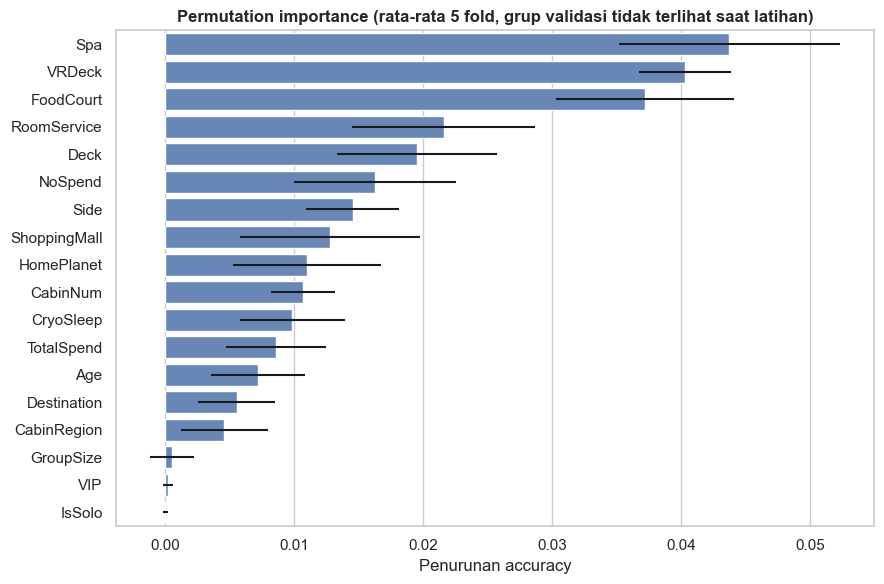

In [40]:
baris = []
for fold, (idx_latih, idx_valid) in enumerate(
        StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, groups)):
    model_fold = clone(pencarian_final.best_estimator_).fit(X.iloc[idx_latih], y.iloc[idx_latih])
    pi = permutation_importance(model_fold, X.iloc[idx_valid], y.iloc[idx_valid],
                                scoring="accuracy", n_repeats=5, random_state=SEED, n_jobs=-1)
    for fitur, nilai in zip(SEMUA, pi.importances_mean):
        baris.append({"fold": fold, "fitur": fitur, "penurunan_accuracy": nilai})

tabel_pi = (pd.DataFrame(baris).groupby("fitur")["penurunan_accuracy"].agg(["mean", "std"])
              .rename(columns={"mean": "penurunan_accuracy", "std": "simpangan_baku"})
              .sort_values("penurunan_accuracy", ascending=False).reset_index())

plt.figure(figsize=(9, 6))
sns.barplot(data=tabel_pi, x="penurunan_accuracy", y="fitur", color="#5b84c4", xerr=tabel_pi["simpangan_baku"])
plt.title("Permutation importance (rata-rata 5 fold, grup validasi tidak terlihat saat latihan)", fontsize=12, fontweight="bold")
plt.xlabel("Penurunan accuracy")
plt.ylabel("")
plt.tight_layout()
plt.show()

Temuan: fitur paling berpengaruh adalah kolom belanja (`Spa`, `VRDeck`, `FoodCourt`, `RoomService`), disusul `Deck`, `NoSpend`, dan `Side`. `GroupSize`, `VIP`, dan `IsSolo` hampir tidak berpengaruh dan `CabinRegion` kecil, sejalan dengan ablation. `CryoSleep` dan `TotalSpend` tampak kecil padahal paling informatif menurut mutual information; kemungkinan karena informasi yang sama tersedia dari kolom belanja individual, bukan karena keduanya tidak penting. Simpangan baku antar fold cukup besar untuk beberapa fitur, jadi urutan di tengah daftar tidak bisa dibaca terlalu tegas.

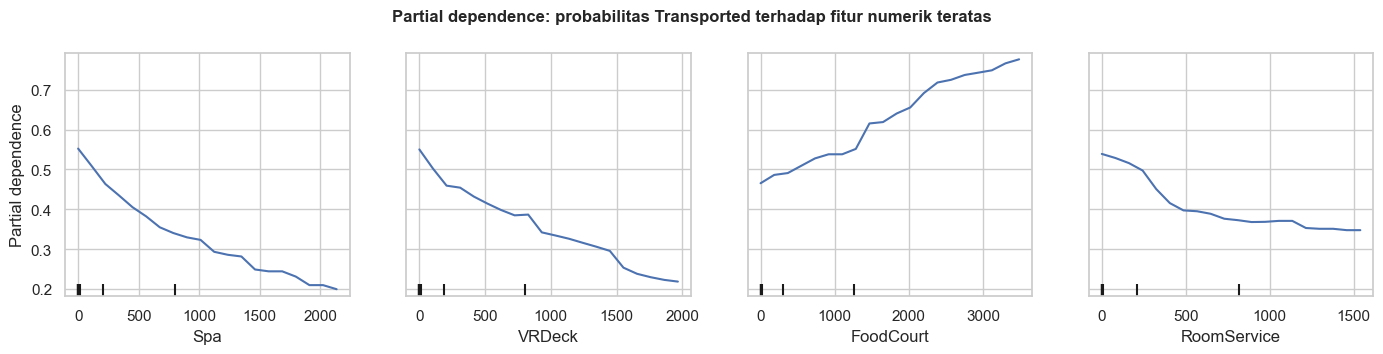

In [41]:
# Partial dependence untuk empat fitur numerik teratas menurut permutation importance
fitur_pdp = [f for f in tabel_pi["fitur"] if f in NUM][:4]
model_pdp = clone(pencarian_final.best_estimator_).fit(X, y)

tampilan = PartialDependenceDisplay.from_estimator(model_pdp, X, fitur_pdp, kind="average", subsample=2000,
                                                   grid_resolution=20, random_state=SEED, n_jobs=-1, n_cols=4)
tampilan.figure_.set_size_inches(14, 3.6)
tampilan.figure_.suptitle("Partial dependence: probabilitas Transported terhadap fitur numerik teratas", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

Temuan: probabilitas Transported turun bila belanja di `Spa`, `VRDeck`, dan `RoomService` naik, tetapi naik bila belanja di `FoodCourt` naik. Pola ini sejalan dengan rate pembelanja besar di bagian Outlier. Partial dependence mengabaikan korelasi antar fitur, jadi kurva hanya menggambarkan kecenderungan model, bukan efek sebab-akibat.

## Analisis kesalahan

Prediksi out-of-fold dari model final (5-fold StratifiedGroupKFold, tiap grup hanya muncul di satu fold validasi) dipakai untuk melihat pola kesalahan. Hyperparameter model final dipilih dari seluruh data latih, jadi skor di sini sedikit optimis. Bagian ini untuk membaca pola kesalahan, bukan untuk melaporkan performa.

              precision    recall  f1-score   support

       False      0.831     0.795     0.813      4315
        True      0.806     0.841     0.823      4378

    accuracy                          0.818      8693
   macro avg      0.819     0.818     0.818      8693
weighted avg      0.819     0.818     0.818      8693



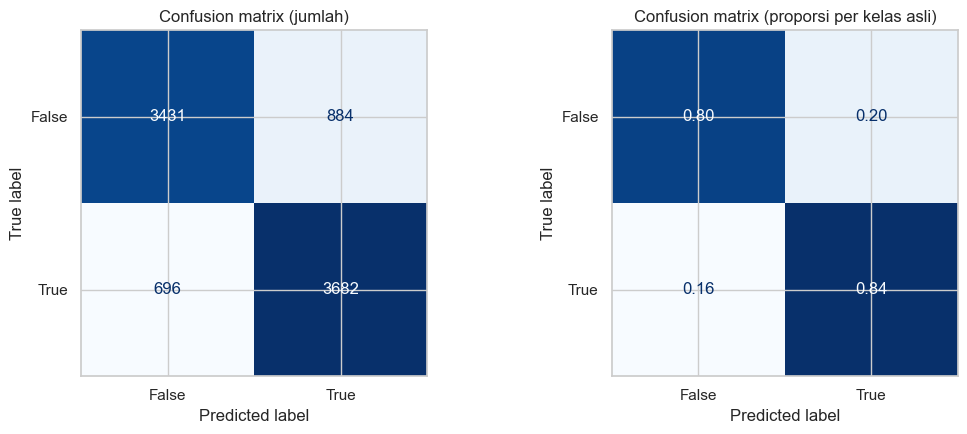

In [42]:
cv_oof = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
proba_oof = cross_val_predict(clone(pencarian_final.best_estimator_), X, y, groups=groups,
                              cv=cv_oof, method="predict_proba", n_jobs=-1)[:, 1]
pred_oof = (proba_oof >= 0.5).astype(int)

print(classification_report(y, pred_oof, target_names=["False", "True"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y, pred_oof, display_labels=["False", "True"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (jumlah)")
ConfusionMatrixDisplay.from_predictions(y, pred_oof, display_labels=["False", "True"], normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title("Confusion matrix (proporsi per kelas asli)")
plt.tight_layout()
plt.show()

Precision kedua kelas hampir sama, tetapi recall kelas True sedikit lebih tinggi daripada kelas False, jadi model sedikit lebih condong memprediksi True. Kecenderungan itu terlihat juga pada proporsi prediksi True di data uji (fase Deployment). Accuracy out-of-fold dekat dengan skor nested CV, dengan selisih kecil yang sesuai dengan sedikit optimisme dari pemilihan hyperparameter pada seluruh data.

In [43]:
hasil_oof = X.copy()
hasil_oof["benar"] = (pred_oof == y.values)
hasil_oof["kelompok_usia"] = pd.cut(X["Age"], [-0.1, 12, 17, 25, 40, 60, 100]).astype(str)
hasil_oof["ukuran_grup"] = np.where(X["GroupSize"] >= 4, "4+", X["GroupSize"].astype(int).astype(str))

baris = []
for kolom in ["CryoSleep", "HomePlanet", "Destination", "Deck", "kelompok_usia", "ukuran_grup"]:
    g = hasil_oof.groupby(hasil_oof[kolom].astype(str))["benar"].agg(["mean", "size"])
    g = g[(g["size"] >= 100) & (g.index != "nan")]
    for kategori, r in g.iterrows():
        baris.append({"fitur": kolom, "kategori": kategori, "accuracy": r["mean"], "n": int(r["size"])})

tabel_segmen = pd.DataFrame(baris).sort_values("accuracy").reset_index(drop=True)
print(f"Accuracy out-of-fold keseluruhan: {hasil_oof['benar'].mean():.4f}")
print("Segmen dengan n >= 100, diurutkan dari accuracy terendah:")
display(tabel_segmen)

Accuracy out-of-fold keseluruhan: 0.8182
Segmen dengan n >= 100, diurutkan dari accuracy terendah:


,fitur,kategori,accuracy,n
0,Deck,G,0.717468,2559
1,kelompok_usia,"(-0.1, 12.0]",0.727047,806
2,Destination,PSO J318.5-22,0.734925,796
3,HomePlanet,Earth,0.747397,4707
4,Deck,E,0.796804,876
5,kelompok_usia,"(17.0, 25.0]",0.803063,2351
6,ukuran_grup,1,0.804162,4805
7,ukuran_grup,4+,0.810287,1186
8,Destination,TRAPPIST-1e,0.810989,5915
9,CryoSleep,0.0,0.817200,5558


Accuracy paling rendah ada pada penumpang Earth dan Deck G, serta pada anak-anak. Earth dan Deck G saling tumpang tindih karena Deck G hanya berisi penumpang Earth (aturan yang dibuktikan di Data Logic), jadi keduanya kemungkinan menunjukkan kelompok yang sama. Pada anak sampai 12 tahun, belanja otomatis nol sehingga sinyal belanja hilang; ini dugaan penyebab, belum diuji. Accuracy tertinggi ada pada Europa serta Deck B dan C, tempat proporsi Transported memang tinggi. Perbedaan antar segmen belum diuji secara statistik, jadi selisih kecil jangan ditafsirkan berlebihan; yang menonjol hanya segmen dengan accuracy jauh di bawah rata-rata keseluruhan.

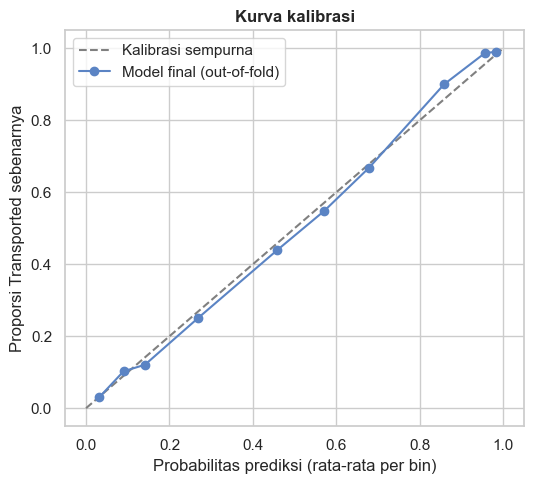

Brier score model: 0.1233 | acuan (selalu memprediksi rata-rata target): 0.2500


In [44]:
frac_positif, rata_prob = calibration_curve(y, proba_oof, n_bins=10, strategy="quantile")

plt.figure(figsize=(5.5, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Kalibrasi sempurna")
plt.plot(rata_prob, frac_positif, "o-", color="#5b84c4", label="Model final (out-of-fold)")
plt.xlabel("Probabilitas prediksi (rata-rata per bin)")
plt.ylabel("Proporsi Transported sebenarnya")
plt.title("Kurva kalibrasi", fontsize=12, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

brier = brier_score_loss(y, proba_oof)
brier_acuan = y.mean() * (1 - y.mean())
print(f"Brier score model: {brier:.4f} | acuan (selalu memprediksi rata-rata target): {brier_acuan:.4f}")

Kurva sangat dekat diagonal, jadi probabilitas model terkalibrasi baik. Penyimpangannya kecil: prediksi sedikit berlebih di probabilitas menengah dan sedikit kurang di sekitar 0,86. Brier score model jauh di bawah acuan prediksi konstan.

## Interval kepercayaan accuracy

Interval dihitung dengan bootstrap per grup pada prediksi out-of-fold: grup diambil ulang dengan pengembalian 2.000 kali, sehingga anggota satu grup selalu ikut bersama. Interval ini hanya mencerminkan variasi pengambilan penumpang untuk model yang tetap, dan tidak mencakup ketidakpastian pemilihan hyperparameter. Selisih dengan Logistic Regression dihitung berpasangan pada resampling yang sama.

In [45]:
proba_lr = cross_val_predict(pipeline_model("Logistic Regression"), X, y, groups=groups, cv=cv_oof,
                             method="predict_proba", n_jobs=-1)[:, 1]

per_grup = pd.DataFrame({"grup": groups.values,
                         "benar_model": (pred_oof == y.values).astype(int),
                         "benar_lr": ((proba_lr >= 0.5).astype(int) == y.values).astype(int)})
ringkas_grup = per_grup.groupby("grup").agg(n=("benar_model", "size"), model=("benar_model", "sum"), lr=("benar_lr", "sum"))

rng_boot = np.random.default_rng(SEED)
ulang = rng_boot.integers(0, len(ringkas_grup), size=(2000, len(ringkas_grup)))
n_boot = ringkas_grup["n"].to_numpy()[ulang].sum(axis=1)
acc_model = ringkas_grup["model"].to_numpy()[ulang].sum(axis=1) / n_boot
acc_lr = ringkas_grup["lr"].to_numpy()[ulang].sum(axis=1) / n_boot
selisih_boot = acc_model - acc_lr


def ci(a):
    return np.percentile(a, [2.5, 97.5])


print(f"Accuracy model final (OOF)     : {ringkas_grup['model'].sum() / ringkas_grup['n'].sum():.4f}  CI 95% {ci(acc_model).round(4)}")
print(f"Accuracy Logistic Regression   : {ringkas_grup['lr'].sum() / ringkas_grup['n'].sum():.4f}  CI 95% {ci(acc_lr).round(4)}")
print(f"Selisih model - Logistic Regr. : {(acc_model - acc_lr).mean():.4f}  CI 95% {ci(selisih_boot).round(4)}")
print(f"Proporsi resampling dengan model lebih baik: {(selisih_boot > 0).mean():.3f}")

Accuracy model final (OOF)     : 0.8182  CI 95% [0.8098 0.8266]
Accuracy Logistic Regression   : 0.7768  CI 95% [0.7672 0.786 ]
Selisih model - Logistic Regr. : 0.0414  CI 95% [0.0345 0.0486]
Proporsi resampling dengan model lebih baik: 1.000


Temuan: interval 95% accuracy model final tidak tumpang tindih dengan interval Logistic Regression, dan pada semua resampling model final lebih baik. Titik tengah interval sedikit optimis karena hyperparameter model final dipilih dari seluruh data latih.

## Peninjauan terhadap kriteria keberhasilan

Tiap kriteria dari fase Business Understanding diperiksa dengan kode. Ambang 0,05 untuk skor label acak ditetapkan secara manual sebagai batas kewajaran.

In [46]:
terpilih = hasil_nested[model_terbaik]["accuracy"].values
dummy_fold = default_sama["Dummy (baseline)"]["accuracy"].values
lr_fold = default_sama["Logistic Regression"]["accuracy"].values
selisih_lr = terpilih - lr_fold

grup_terpecah = any(
    set(groups.iloc[tr]) & set(groups.iloc[va])
    for tr, va in cv_luar.split(X, y, groups)
)
auc_acak = r_acak_final["test_roc_auc"].mean()

kriteria = pd.DataFrame([
    ("1a. Lebih baik dari Dummy di semua fold luar",
     f"{(terpilih > dummy_fold).sum()}/{len(terpilih)} fold", bool((terpilih > dummy_fold).all())),
    ("1b. Lebih baik dari Logistic Regression di mayoritas fold dan selisih rata-rata > simpangan baku selisih",
     f"{(selisih_lr > 0).sum()}/{len(selisih_lr)} fold; selisih {selisih_lr.mean():.4f} (simpangan baku {selisih_lr.std():.4f})",
     bool((selisih_lr > 0).sum() > len(selisih_lr) / 2 and selisih_lr.mean() > selisih_lr.std())),
    ("2a. Tidak ada grup yang terpecah antara latih dan validasi",
     "ada grup terpecah" if grup_terpecah else "tidak ada grup terpecah", not grup_terpecah),
    ("2b. AUC label acak dalam 0,05 dari tingkat kebetulan (0,5)",
     f"AUC {auc_acak:.3f}", bool(abs(auc_acak - 0.5) < 0.05)),
], columns=["kriteria", "hasil", "terpenuhi"])

pd.set_option("display.max_colwidth", None)
display(kriteria)
print("Kriteria 3 (dilaporkan sebagai rata-rata ± simpangan baku) dipenuhi pada bagian Ringkasan di bawah.")

,kriteria,hasil,terpenuhi
0,1a. Lebih baik dari Dummy di semua fold luar,5/5 fold,True
1,1b. Lebih baik dari Logistic Regression di mayoritas fold dan selisih rata-rata > simpangan baku selisih,5/5 fold; selisih 0.0388 (simpangan baku 0.0080),True
2,2a. Tidak ada grup yang terpecah antara latih dan validasi,tidak ada grup terpecah,True
3,"2b. AUC label acak dalam 0,05 dari tingkat kebetulan (0,5)",AUC 0.513,True


Kriteria 3 (dilaporkan sebagai rata-rata ± simpangan baku) dipenuhi pada bagian Ringkasan di bawah.


## Ringkasan

In [47]:
nested_terbaik = hasil_nested[model_terbaik]
lr = hasil_default["Logistic Regression"]
dummy = hasil_default["Dummy (baseline)"]
print(f"Baseline (Dummy)        : accuracy {dummy['accuracy'].mean():.4f} ± {dummy['accuracy'].std():.4f}")
print(f"Logistic Regression     : accuracy {lr['accuracy'].mean():.4f} ± {lr['accuracy'].std():.4f}")
print(f"{model_terbaik} (tuning, nested CV): accuracy {nested_terbaik['accuracy'].mean():.4f} ± {nested_terbaik['accuracy'].std():.4f}"
      f" | rentang fold {nested_terbaik['accuracy'].min():.3f}-{nested_terbaik['accuracy'].max():.3f}")
print(f"AUC (nested)            : {nested_terbaik['roc_auc'].mean():.4f} ± {nested_terbaik['roc_auc'].std():.4f}")
print()
print("Batasan: skor berasal dari satu dataset latih dan pembagian fold tertentu;")
print("simpangan baku antar fold menunjukkan ketidakpastiannya. Hubungan antar fitur bersifat asosiatif.")

Baseline (Dummy)        : accuracy 0.4981 ± 0.0113
Logistic Regression     : accuracy 0.7759 ± 0.0123
CatBoost (tuning, nested CV): accuracy 0.8156 ± 0.0168 | rentang fold 0.792-0.829
AUC (nested)            : 0.9068 ± 0.0120

Batasan: skor berasal dari satu dataset latih dan pembagian fold tertentu;
simpangan baku antar fold menunjukkan ketidakpastiannya. Hubungan antar fitur bersifat asosiatif.


## Perbandingan dengan skor leaderboard

Setelah model final ditentukan, `data/submission.csv` dikirim ke Kaggle satu kali. Skor publiknya tidak dipakai untuk memilih model atau hyperparameter. Nilainya diisi manual sebagai konstanta karena berasal dari luar notebook.

Selisih dengan skor validasi dibandingkan dengan dua sumber ketidakpastian: pengambilan sampel data uji (dihitung dari jumlah barisnya, dengan anggapan seluruh baris dipakai untuk skor publik) dan galat estimasi validasi (dari interval bootstrap per grup). Keduanya digabung dengan pendekatan normal, jadi hasilnya perkiraan kasar.

In [48]:
# Skor publik Kaggle untuk data/submission.csv (satu submisi), diisi manual dari halaman Kaggle
SKOR_LEADERBOARD = 0.8043

se_uji = np.sqrt(SKOR_LEADERBOARD * (1 - SKOR_LEADERBOARD) / len(data_uji))
se_validasi = (ci(acc_model)[1] - ci(acc_model)[0]) / (2 * 1.96)
se_gabungan = np.hypot(se_uji, se_validasi)

baris = []
for nama, nilai in [("Nested CV (skor yang dilaporkan)", nested_terbaik["accuracy"].mean()),
                    ("Out-of-fold model final", ringkas_grup["model"].sum() / ringkas_grup["n"].sum())]:
    baris.append({"skor validasi": nama, "accuracy validasi": nilai, "accuracy leaderboard": SKOR_LEADERBOARD,
                  "selisih": nilai - SKOR_LEADERBOARD, "selisih / galat gabungan": (nilai - SKOR_LEADERBOARD) / se_gabungan})
display(pd.DataFrame(baris).set_index("skor validasi"))
print(f"Galat pengambilan sampel data uji: {se_uji:.4f} | galat estimasi validasi: {se_validasi:.4f} | gabungan: {se_gabungan:.4f}")

,accuracy validasi,accuracy leaderboard,selisih,selisih / galat gabungan
skor validasi,,,,
Nested CV (skor yang dilaporkan),0.815566,0.8043,0.011266,1.517307
Out-of-fold model final,0.818245,0.8043,0.013945,1.878096


Galat pengambilan sampel data uji: 0.0061 | galat estimasi validasi: 0.0043 | gabungan: 0.0074


Skor leaderboard lebih rendah daripada skor validasi, dan selisihnya sekitar satu setengah kali galat gabungan, jadi masih wajar terjadi karena kebetulan. Penyebab lain yang mungkin adalah sedikit optimisme dari pemilihan hyperparameter dan pemilihan model pada data yang sama; keduanya dugaan, bukan hasil pengujian. Adversarial validation tidak menemukan pergeseran sebaran fitur, jadi pergeseran data bukan penjelasan utama. Satu submisi belum cukup untuk menyimpulkan lebih jauh.

## Kesimpulan dan batasan

- Model terpilih adalah CatBoost dengan fitur hasil imputasi struktural dan feature engineering. Skor yang dapat dilaporkan adalah skor nested CV di bagian Ringkasan.
- Semua model boosting lebih baik daripada Logistic Regression di semua fold. Perbedaan antar model boosting kecil dibanding sebaran antar fold, dan memilih pemenang dari empat kandidat pada fold luar yang sama membuat skor pemenangnya sedikit optimis.
- Ablation tidak membuktikan bahwa `CabinRegion` dan fitur grup (`GroupSize`, `IsSolo`) membantu. Fitur lokasi kabin secara keseluruhan (`Deck`, `CabinNum`, `Side`) terukur berguna.
- Tuning hyperparameter tidak memberi perbaikan yang terbukti pada keempat kandidat dibandingkan pengaturan default, dan fitur tambahan serta ensemble juga tidak memberi perbaikan yang terbukti.
- Pemeriksaan label acak tidak menunjukkan kebocoran, tetapi tidak membuktikan ketiadaannya sepenuhnya.
- Accuracy paling rendah ada pada penumpang Earth (Deck G) dan anak-anak, sedangkan kalibrasi probabilitas baik.
- Skor leaderboard publik sedikit di bawah skor nested CV. Selisihnya sekitar satu setengah kali galat gabungan, jadi wajar terjadi karena kebetulan.
- Hubungan antara fitur dan target bersifat asosiatif, bukan sebab-akibat.
- Skor berasal dari satu dataset latih; ketidakpastiannya tercermin dari simpangan baku antar fold dan interval bootstrap.

## Tinjauan proses dan langkah lanjut

- Setiap aturan imputasi dibuktikan lebih dulu pada data. Nilai kosong yang tidak bisa dipastikan diserahkan ke Pipeline per fold, dan pola nilai kosong yang tampak acak mendukung pilihan itu.
- Hipotesis fitur (`CabinRegion`, fitur grup) dan fitur tambahan lain diuji lewat ablation dan eksperimen, dan tidak terbukti membantu. Fitur awal tetap dipakai supaya skor yang dilaporkan sesuai dengan fitur di model; membuangnya bisa dicoba pada iterasi berikutnya.
- Skor leaderboard baru dari satu submisi, dan tidak dipakai untuk memilih model. Satu submisi belum cukup untuk menyimpulkan apa pun lebih jauh.
- Belum dicoba: LightGBM dan imputasi berbasis model.

# 6. Deployment

## Model akhir dan prediksi data uji

Model terpilih dilatih ulang pada seluruh data latih dengan hyperparameter final, lalu dipakai memprediksi data uji. Performa yang diharapkan sama dengan skor nested CV di bagian Ringkasan beserta simpangan bakunya, bukan skor pada data latih.

In [49]:
model_akhir = clone(pencarian_final.best_estimator_)
model_akhir.fit(X, y)

X_test = data_uji[SEMUA]
assert list(X_test.columns) == list(X.columns), "Kolom data uji berbeda dari data latih"

prediksi = model_akhir.predict(X_test).astype(bool)

submisi = pd.DataFrame({"PassengerId": data_uji["PassengerId"].values, "Transported": prediksi})

# Cek sebelum menyimpan
assert len(submisi) == len(sample)
assert (submisi["PassengerId"].values == sample["PassengerId"].values).all(), "Urutan berbeda dari sample_submission"
assert submisi["Transported"].notna().all()

SUBMISI_PATH = Path("data/submission.csv")
submisi.to_csv(SUBMISI_PATH, index=False)

cek = pd.read_csv(SUBMISI_PATH)
print("Bentuk submisi:", cek.shape, "| kolom:", list(cek.columns))
print("Proporsi prediksi True (data uji)  :", round(cek["Transported"].mean(), 4))
print("Proporsi True pada data latih      :", round(y.mean(), 4))
display(cek.head())

Bentuk submisi: (4277, 2) | kolom: ['PassengerId', 'Transported']
Proporsi prediksi True (data uji)  : 0.5305
Proporsi True pada data latih      : 0.5036


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


In [50]:
print(f"Waktu eksekusi seluruh notebook: {(time.time() - T_MULAI) / 60:.1f} menit")

Waktu eksekusi seluruh notebook: 26.0 menit


## Rencana pemakaian dan pemeliharaan

Keluaran notebook ini adalah `data/submission.csv`, berformat sama dengan `sample_submission.csv`. Notebook tidak membangun layanan prediksi. Jika model dipakai ulang pada data penumpang baru:

- Data baru harus melalui aturan imputasi struktural dan fitur turunan yang sama, lalu model akhir (Pipeline lengkap) dipakai untuk prediksi.
- Pantau proporsi nilai kosong dan sebaran fitur dibanding data latih. Jika bergeser jauh, evaluasi ulang dan latih ulang model.
- Prediksi bersifat asosiatif dan hanya sebaik sebaran data latih; jangan dipakai untuk menyimpulkan sebab-akibat.